In this notebook we will do a kind of regression with OptDMD modes. The OptDMD reconstruction of our data $Y$ can be written as

$$Y=\begin{bmatrix} \phi_{11} & \phi_{12} & \cdots & \phi_{1r} \\ \phi_{21} & \phi_{22} & \cdots &\phi_{2r} \\ \vdots & \vdots & \ddots & \vdots \\ \phi_{m1} & \phi_{m2} & \cdots & \phi_{mr} \end{bmatrix}
    \begin{bmatrix} b_1 & & & \\ & b_2 & & \\ & & \ddots & \\ & & & b_r \end{bmatrix} \begin{bmatrix} e^{\lambda_1 t_1} & e^{\lambda_1 t_2} & \cdots & e^{\lambda_1 t_n} \\
    e^{\lambda_2 t_1} & e^{\lambda_2 t_2} & \cdots & e^{\lambda_2 t_n} \\ 
    \vdots & \vdots & \ddots & \vdots \\ e^{\lambda_r t_1} & e^{\lambda_r t_2} & \cdots & e^{\lambda_r t_n}\end{bmatrix}.$$

One way to do regression is to find the optimal $b_1,\ldots,b_r$ to minimize the Frobenius norm of the difference between the data at a different time point and the reconstruction. If the data is the same data the model was fit on, then this should just recover the original amplitudes.

# Reconstructing true amplitudes


As a proof of concept, let's see that this works when we try to recover the original amplitudes. Note that you will need the commercial solver MOSEK to run this code as is. You can get a free academic license here: https://www.mosek.com/products/academic-licenses/. Alternatively, you can specify solver='SCS' in the regress_optdmd function. However, I have found the open source solvers to be very slow and produce poor fits.

OptDMD RSE: 0.011769294239880004
Convex Optimization RSE: 0.011657557397278666


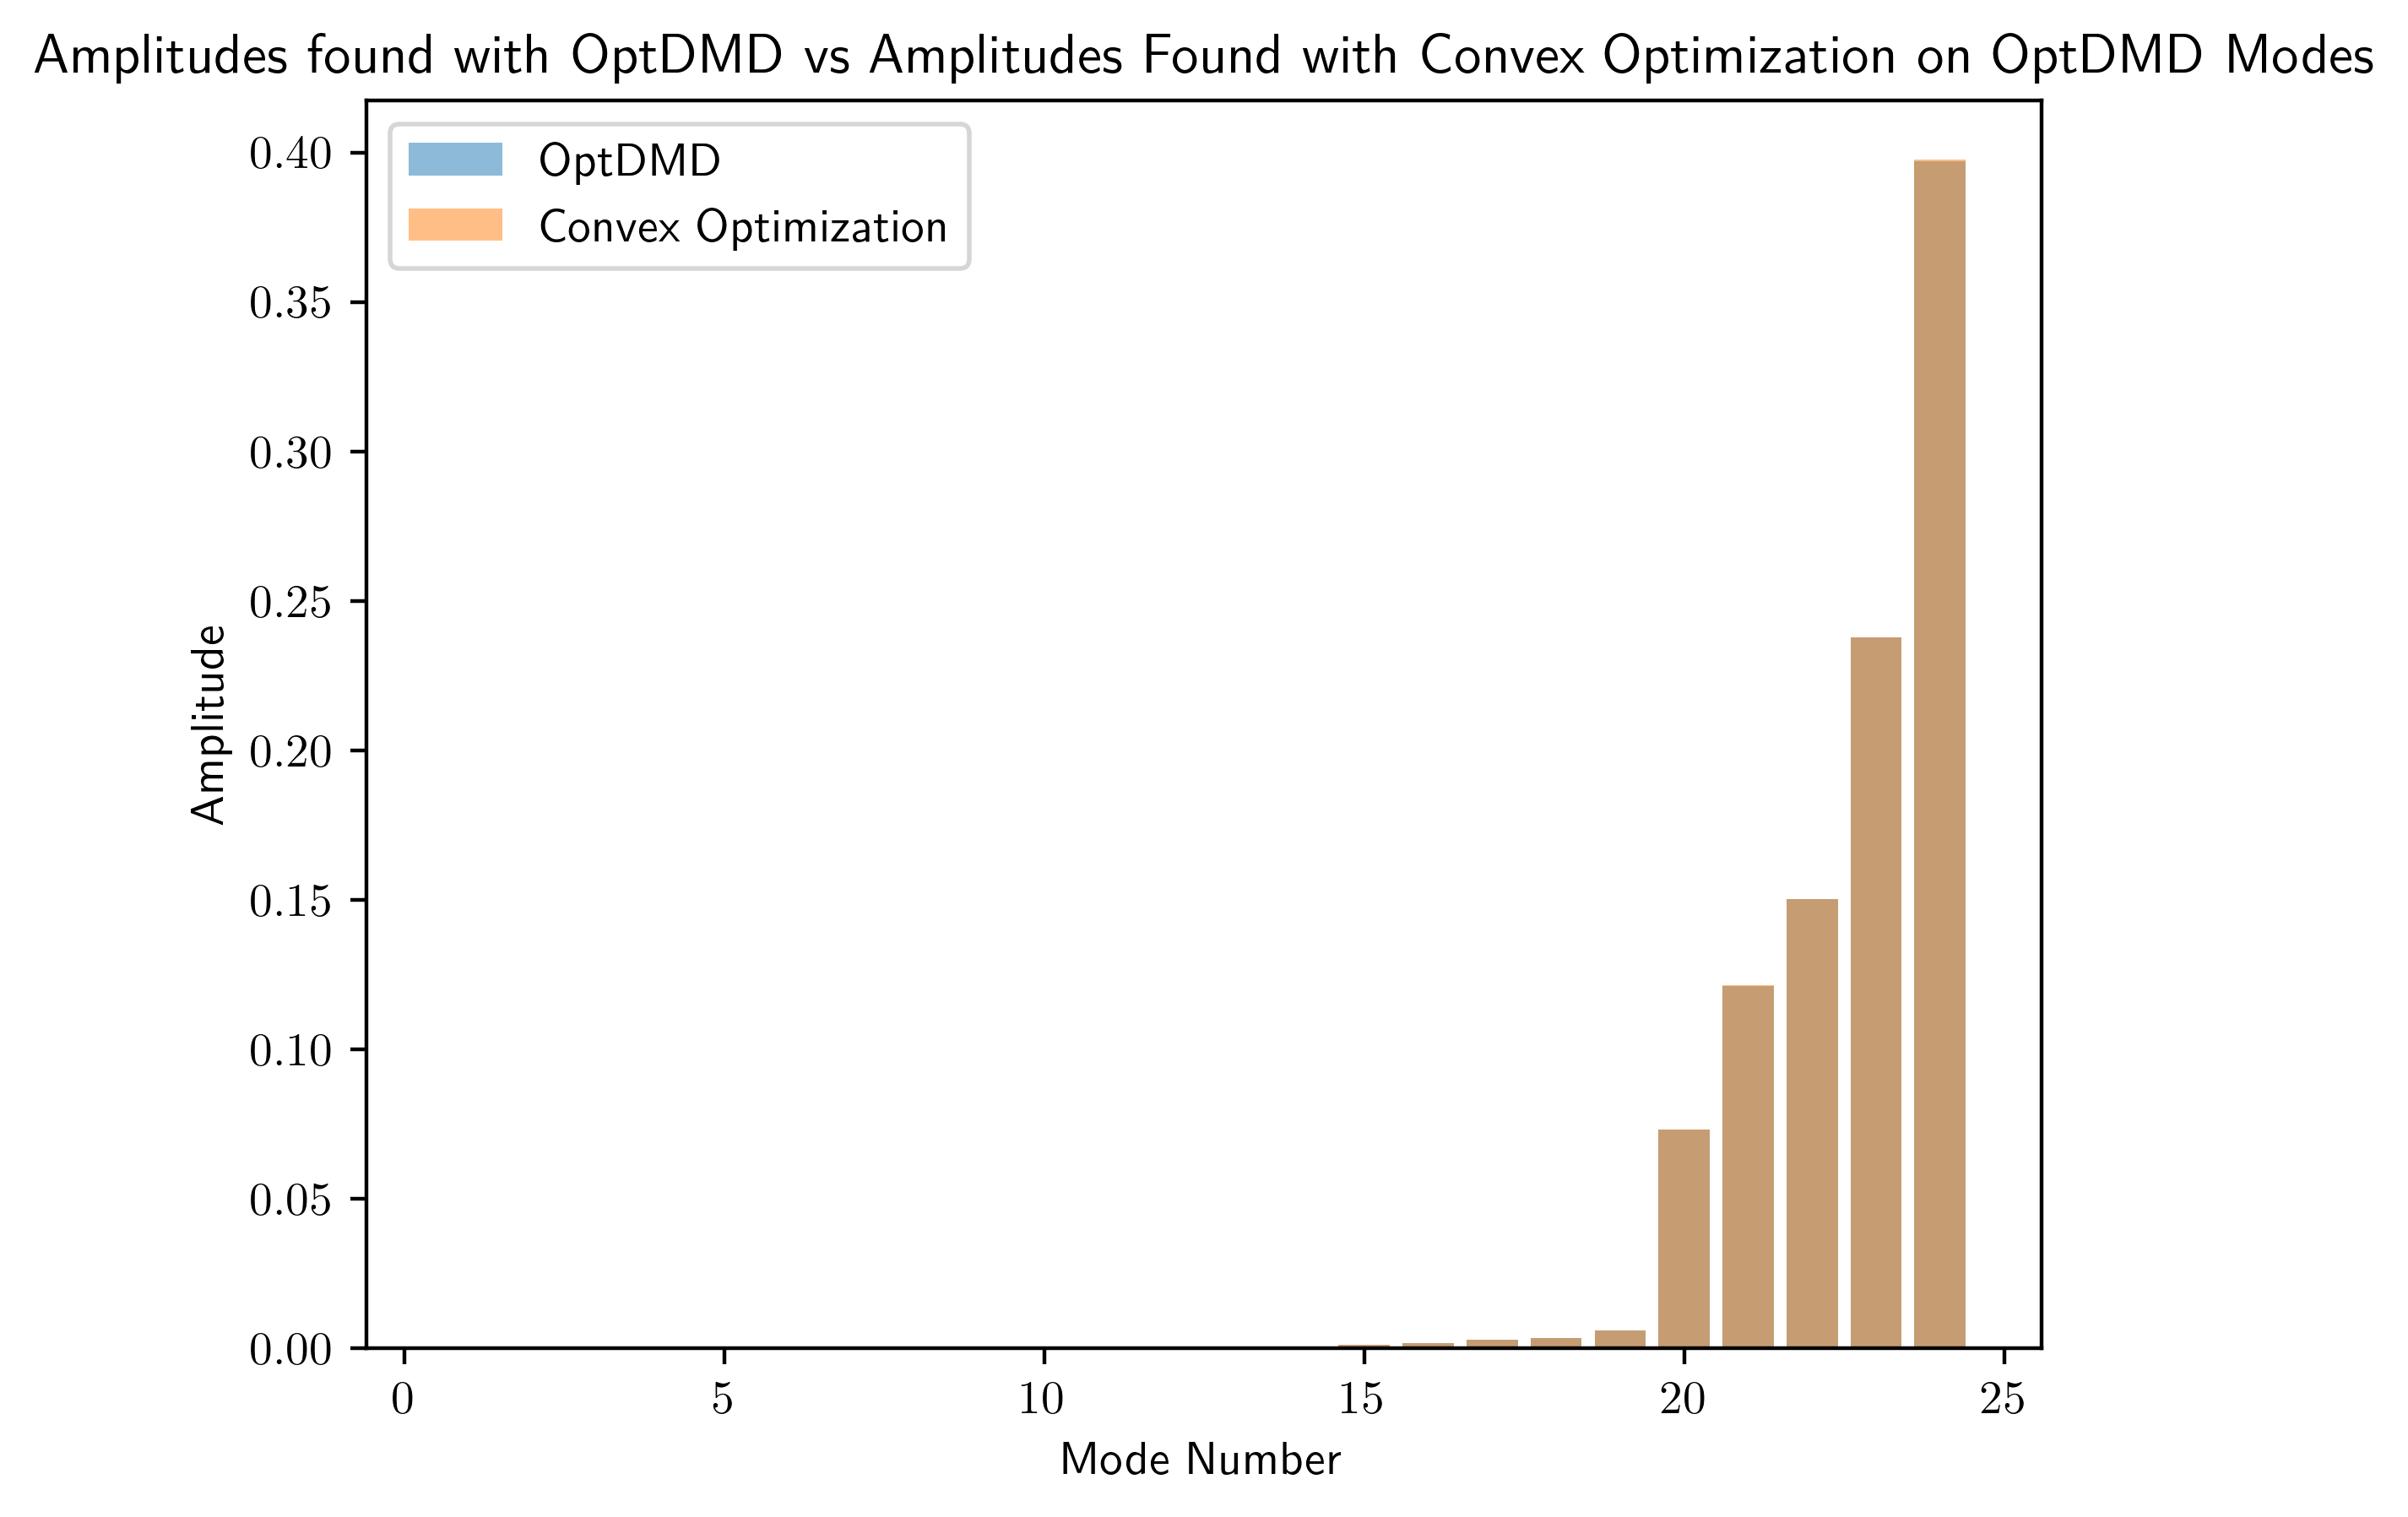

In [2]:
import numpy as np # Matrix and vector algebra
import matplotlib.pylab as plt # Plotting
import pandas as pd # Tables
import warnings
from tqdm.auto import tqdm # Progress bars
import cvxpy as cp
from BopDMD_Regularized import BOPDMD
from typing import Union,Type
from pydmd import HankelDMD
from pydmd.dmdoperator import DMDOperator

np.set_printoptions(suppress=True,precision=8,linewidth=100000) # Improve print statements
plt.rcParams['figure.dpi']=400 # Use higher resolution figures
plt.rcParams['text.usetex']=True # Use LaTeX in plots

def regress_optdmd(Y: np.ndarray, modes_mat: np.ndarray, exp_mat: np.ndarray, 
                   r: int, threshold: float=None, solver: str='MOSEK'):
    """
    Calculates optimal diagonal matrix B.
    Y: m x n matrix of data to fit.
    modes_mat: m x r matrix of spatial modes.
    exp_mat: r x n matrix of exponential dynamics.
    r: rank of fit.
    threshold: minimum value allowed for any amplitude.
    solver: which cvxpy solver to use.
    """
    b = cp.Variable((r,r),diag=True) # Coefficients to find
    if threshold is not None:
        constraints = [b>=cp.diag(np.ones(r)*threshold)]
    else:
        constraints = None
    objective = cp.Minimize(cp.norm(Y-cp.real(modes_mat@b@exp_mat),"fro"))
    prob = cp.Problem(objective, constraints)
    result = prob.solve(solver=solver)
    reconstruct = modes_mat@b.value@exp_mat
    return reconstruct,np.diag(b.value.toarray())

RSE = lambda X,Y: np.sum((Y-np.real(X))**2)/np.sum((Y-np.mean(Y))**2)
# Model reconstruction = X, true data = Y

# Get widefield data
SV = np.load('../Mouse Data/svdTemporalComponents_corr.npy').T
SV_norm = np.linalg.norm(SV)
SVn = SV / SV_norm

# Fit OptDMD
optdmd = BOPDMD(24)
optdmd.fit(SVn[:50,:500],np.arange(500))

# Widefield OptDMD modes
modes_mat = optdmd.modes
t = np.arange(0,500)
# Matrix of exponentials
exp_mat = np.exp(np.outer(optdmd.eigs[np.newaxis],t))

reconstruct, b = regress_optdmd(SVn[:50,:500],modes_mat,exp_mat,24)

print("OptDMD RSE: " + str(RSE(optdmd.reconstructed_data, SVn[:50,:500])))
print("Convex Optimization RSE: " + str(RSE(reconstruct, SVn[:50,:500])))
plt.bar(np.arange(1,25),np.sort(optdmd.amplitudes),alpha=0.5,label="OptDMD")
plt.bar(np.arange(1,25),np.sort(b),alpha=0.5,label="Convex Optimization")
plt.xlabel("Mode Number")
plt.ylabel("Amplitude")
plt.title("Amplitudes found with OptDMD vs Amplitudes Found with Convex Optimization on OptDMD Modes")
plt.legend();

As we can see, cvxpy recovers essentially the same amplitudes as OptDMD, leading to us getting essentially the same RSE.

# Fitting Modes to Future Data

The next question is whether we can get a meaningful reconstruction when we apply this method to future data that the model was not fit on. This is not a true prediction because we are learning the $b$ coefficients from future data, but a high performance here would tell us that the same modes are present at future times, which Aditya has mentioned is sufficient for some control methods.

One thing that's not obvious is how to properly initialize the matrix of exponentials. For now I am just "resetting" it by setting $t_0=0$ and allowing the dynamics to propagate from there.

Forecast RSE: 0.06755686815269418


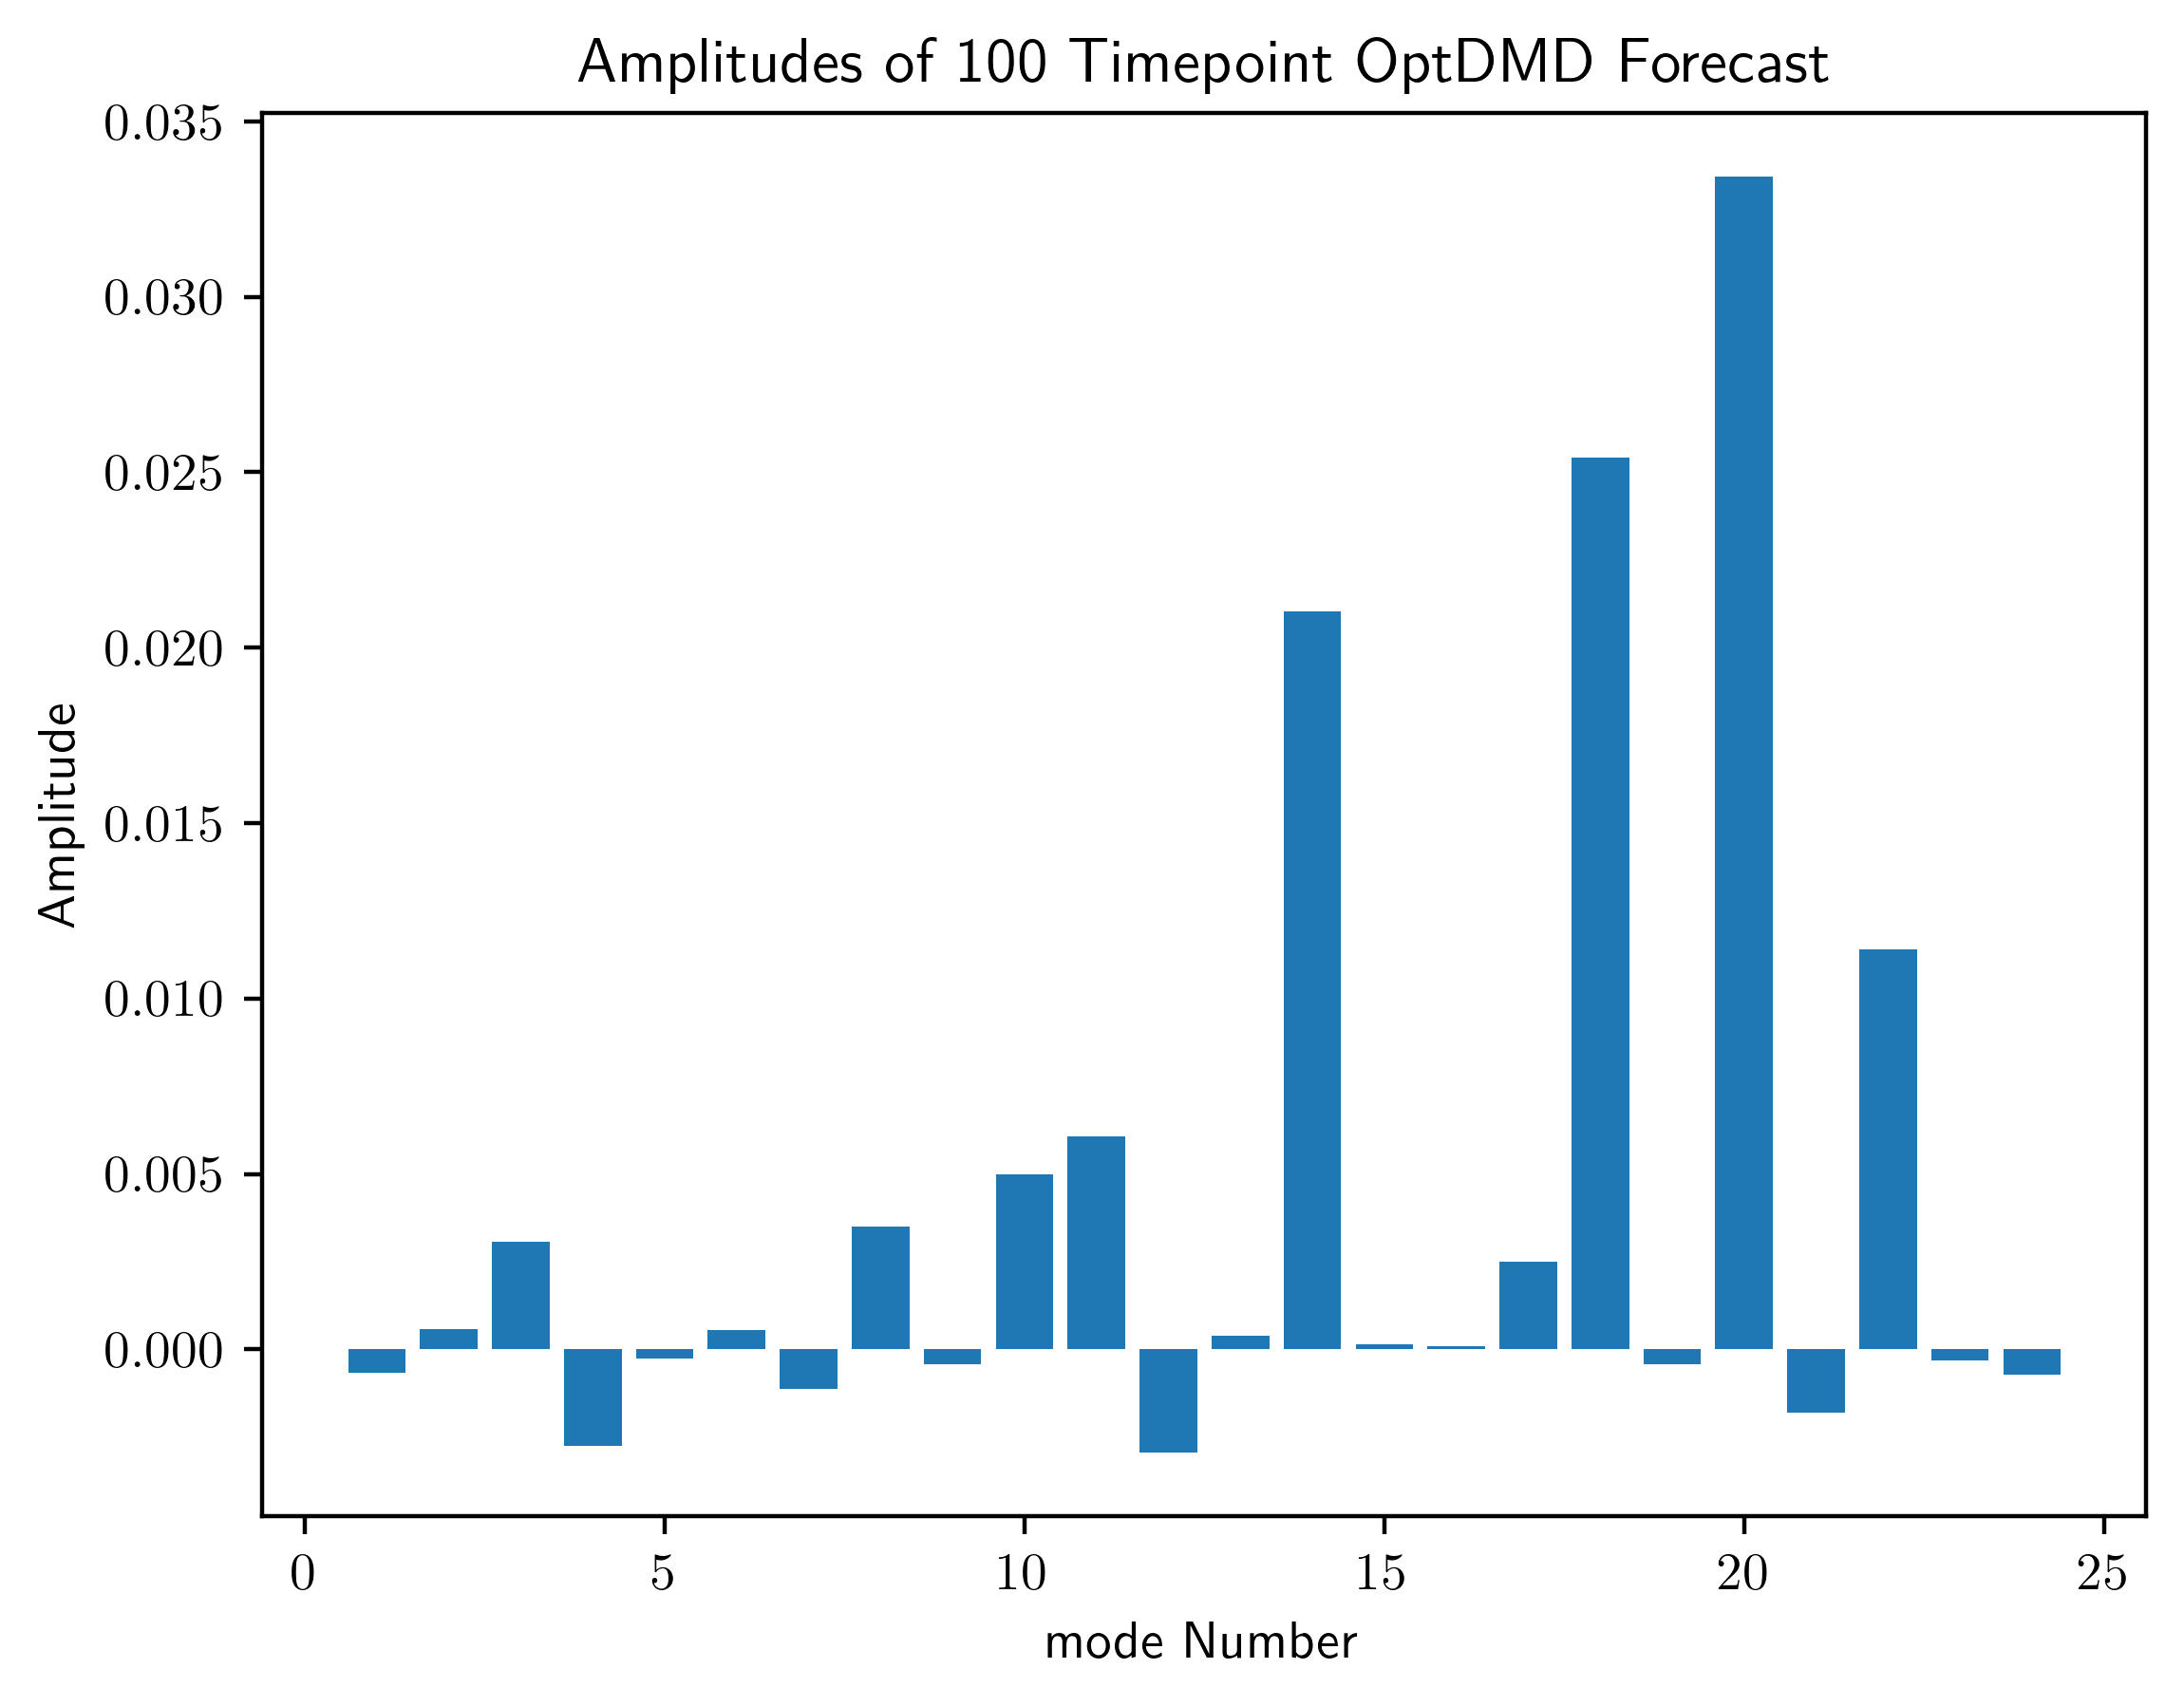

In [32]:
t = np.arange(0,100)
exp_mat = np.exp(np.outer(optdmd.eigs[np.newaxis],t))
reconstruct, b = regress_optdmd(SVn[:50,500:600],optdmd.modes,exp_mat,24)
print("Forecast RSE: " + str(RSE(reconstruct,SVn[:50,500:600])))
plt.bar(np.arange(1,25),b)
plt.xlabel("mode Number")
plt.ylabel("Amplitude")
plt.title("Amplitudes of 100 Timepoint OptDMD Forecast");

So with a fit to 500 timepoints, we can forecast the future 100 seconds with the same modes with less than 7% error. I have repeated this with a 1000 timepoint fit (again with 24 modes) and a 100 timepoint forecast and got 4% reconstruction error on the 1000 timepoints, 17% reconstruction error on the 100 timepoint forecast.

Note that I have allowed negative amplitudes here. The logic here is that a mode that was excited during the period of the OptDMD fit could be inhibited after the training window. We can easily enforce that the amplitudes are all non-negative as well.

Forecast RSE: 0.09019689855238479


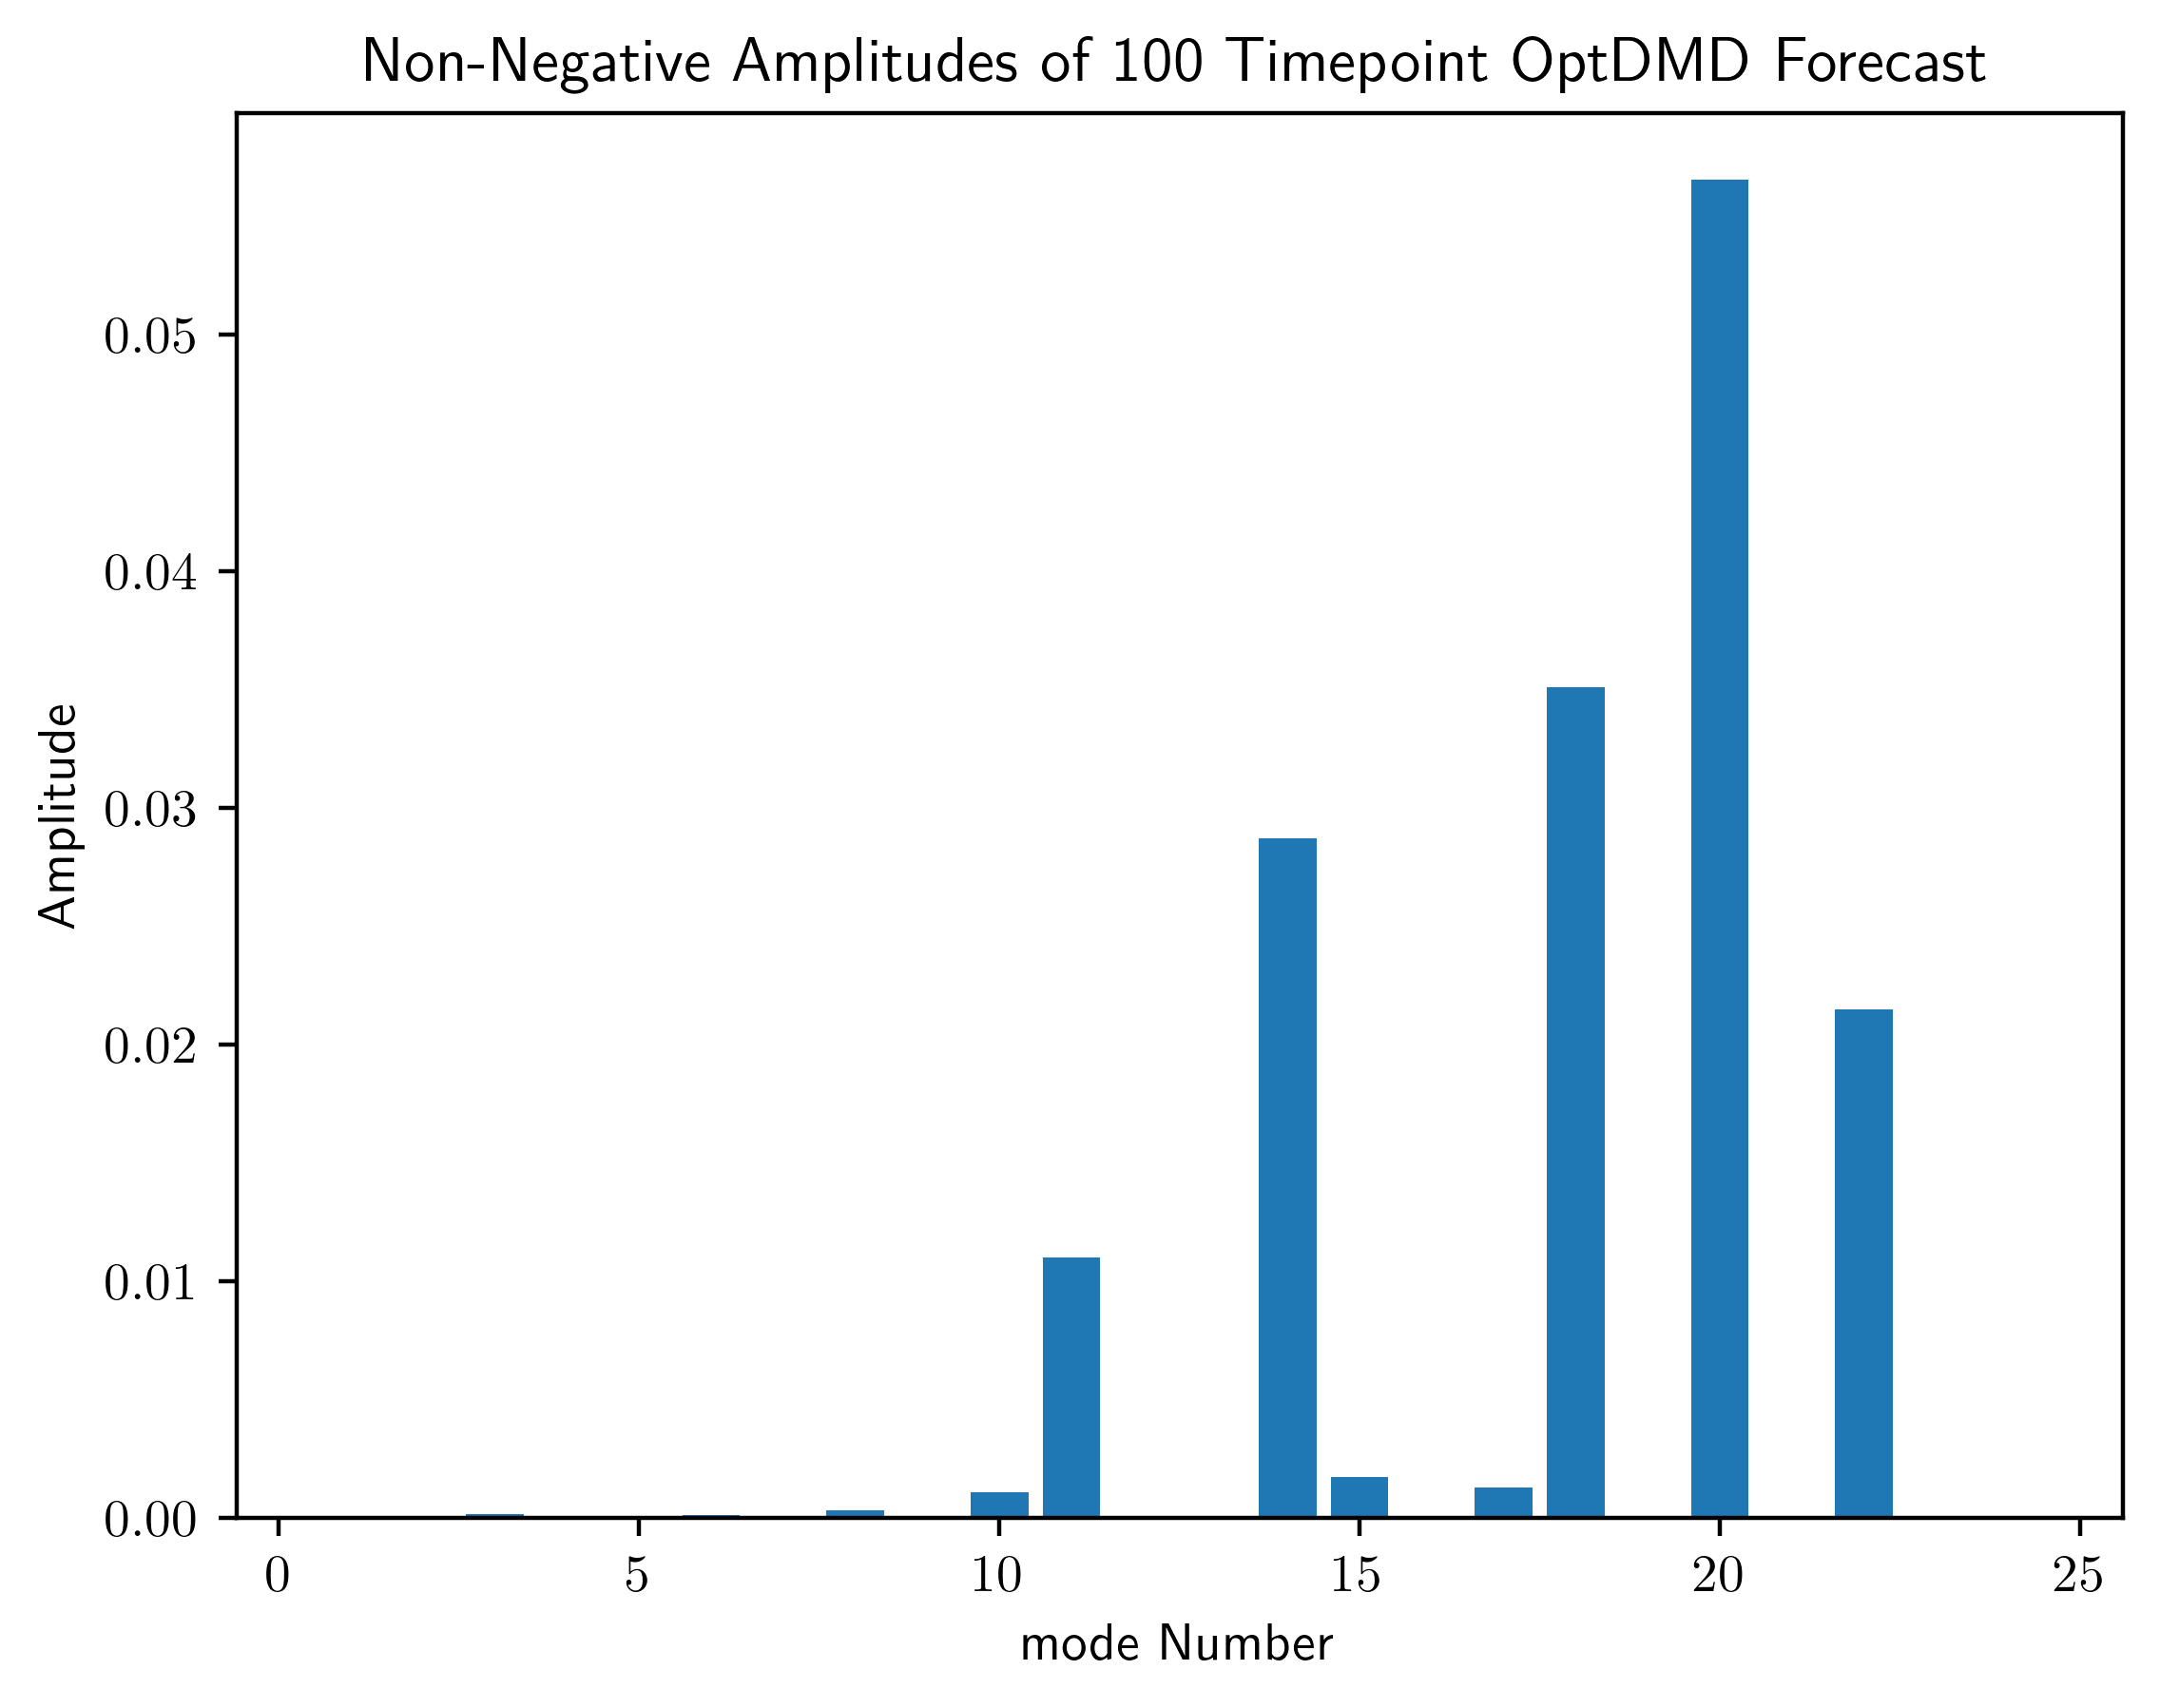

In [40]:
t = np.arange(0,100)
exp_mat = np.exp(np.outer(optdmd.eigs[np.newaxis],t))
reconstruct, b = regress_optdmd(SVn[:50,500:600],optdmd.modes,exp_mat,24,1e-5)
print("Forecast RSE: " + str(RSE(reconstruct,SVn[:50,500:600])))
plt.bar(np.arange(1,25),b)
plt.xlabel("mode Number")
plt.ylabel("Amplitude")
plt.title("Non-Negative Amplitudes of 100 Timepoint OptDMD Forecast");

This gives us a much sparser fit with only a slight increase in reconstruction RSE.

To establish that what we're seeing here is actual temporal stability of our modes and not just an arbitrary way of fitting our data, we need to show that the performance of fitting these modes to future data is worse than the performance of fitting these modes to data immediately after the training period. This is because we expect the modes to be temporally stable for a time but not forever. The following code establishes this. We fit to 500 non-overlapping training periods and then use these modes to fit amplitudes to either the following 100 timepoints or 100 timepoints near the end of the recording. Then we compare the reconstruction RSEs in both cases.

In [275]:
n = 20
immediate_RSEs = np.zeros(n)
future_RSEs = np.zeros(n)
for i in tqdm(range(n)):
    # Organize data windows
    train = SVn[:50,i*500:(i+1)*500]
    immediate = SVn[:50,(i+1)*500:(i+1)*500+100]
    future = SVn[:50,-(i+1)*500-100:-(i+1)*500]
    # Fit OptDMD
    optdmd = BOPDMD(svd_rank=24)
    optdmd.fit(train,np.arange(500))
    # Get matrix of exponentials
    t = np.arange(1,101)
    exp_mat = np.exp(np.outer(optdmd.eigs[np.newaxis],t))
    
    reconstruct_immediate, _ = regress_optdmd(immediate,modes_mat,exp_mat,24,0)
    reconstruct_future,    _ = regress_optdmd(future,modes_mat,exp_mat,24,0)
    immediate_RSEs[i] = RSE(reconstruct_immediate,immediate)
    future_RSEs[i]    = RSE(reconstruct_future,future)

  0%|          | 0/20 [00:00<?, ?it/s]

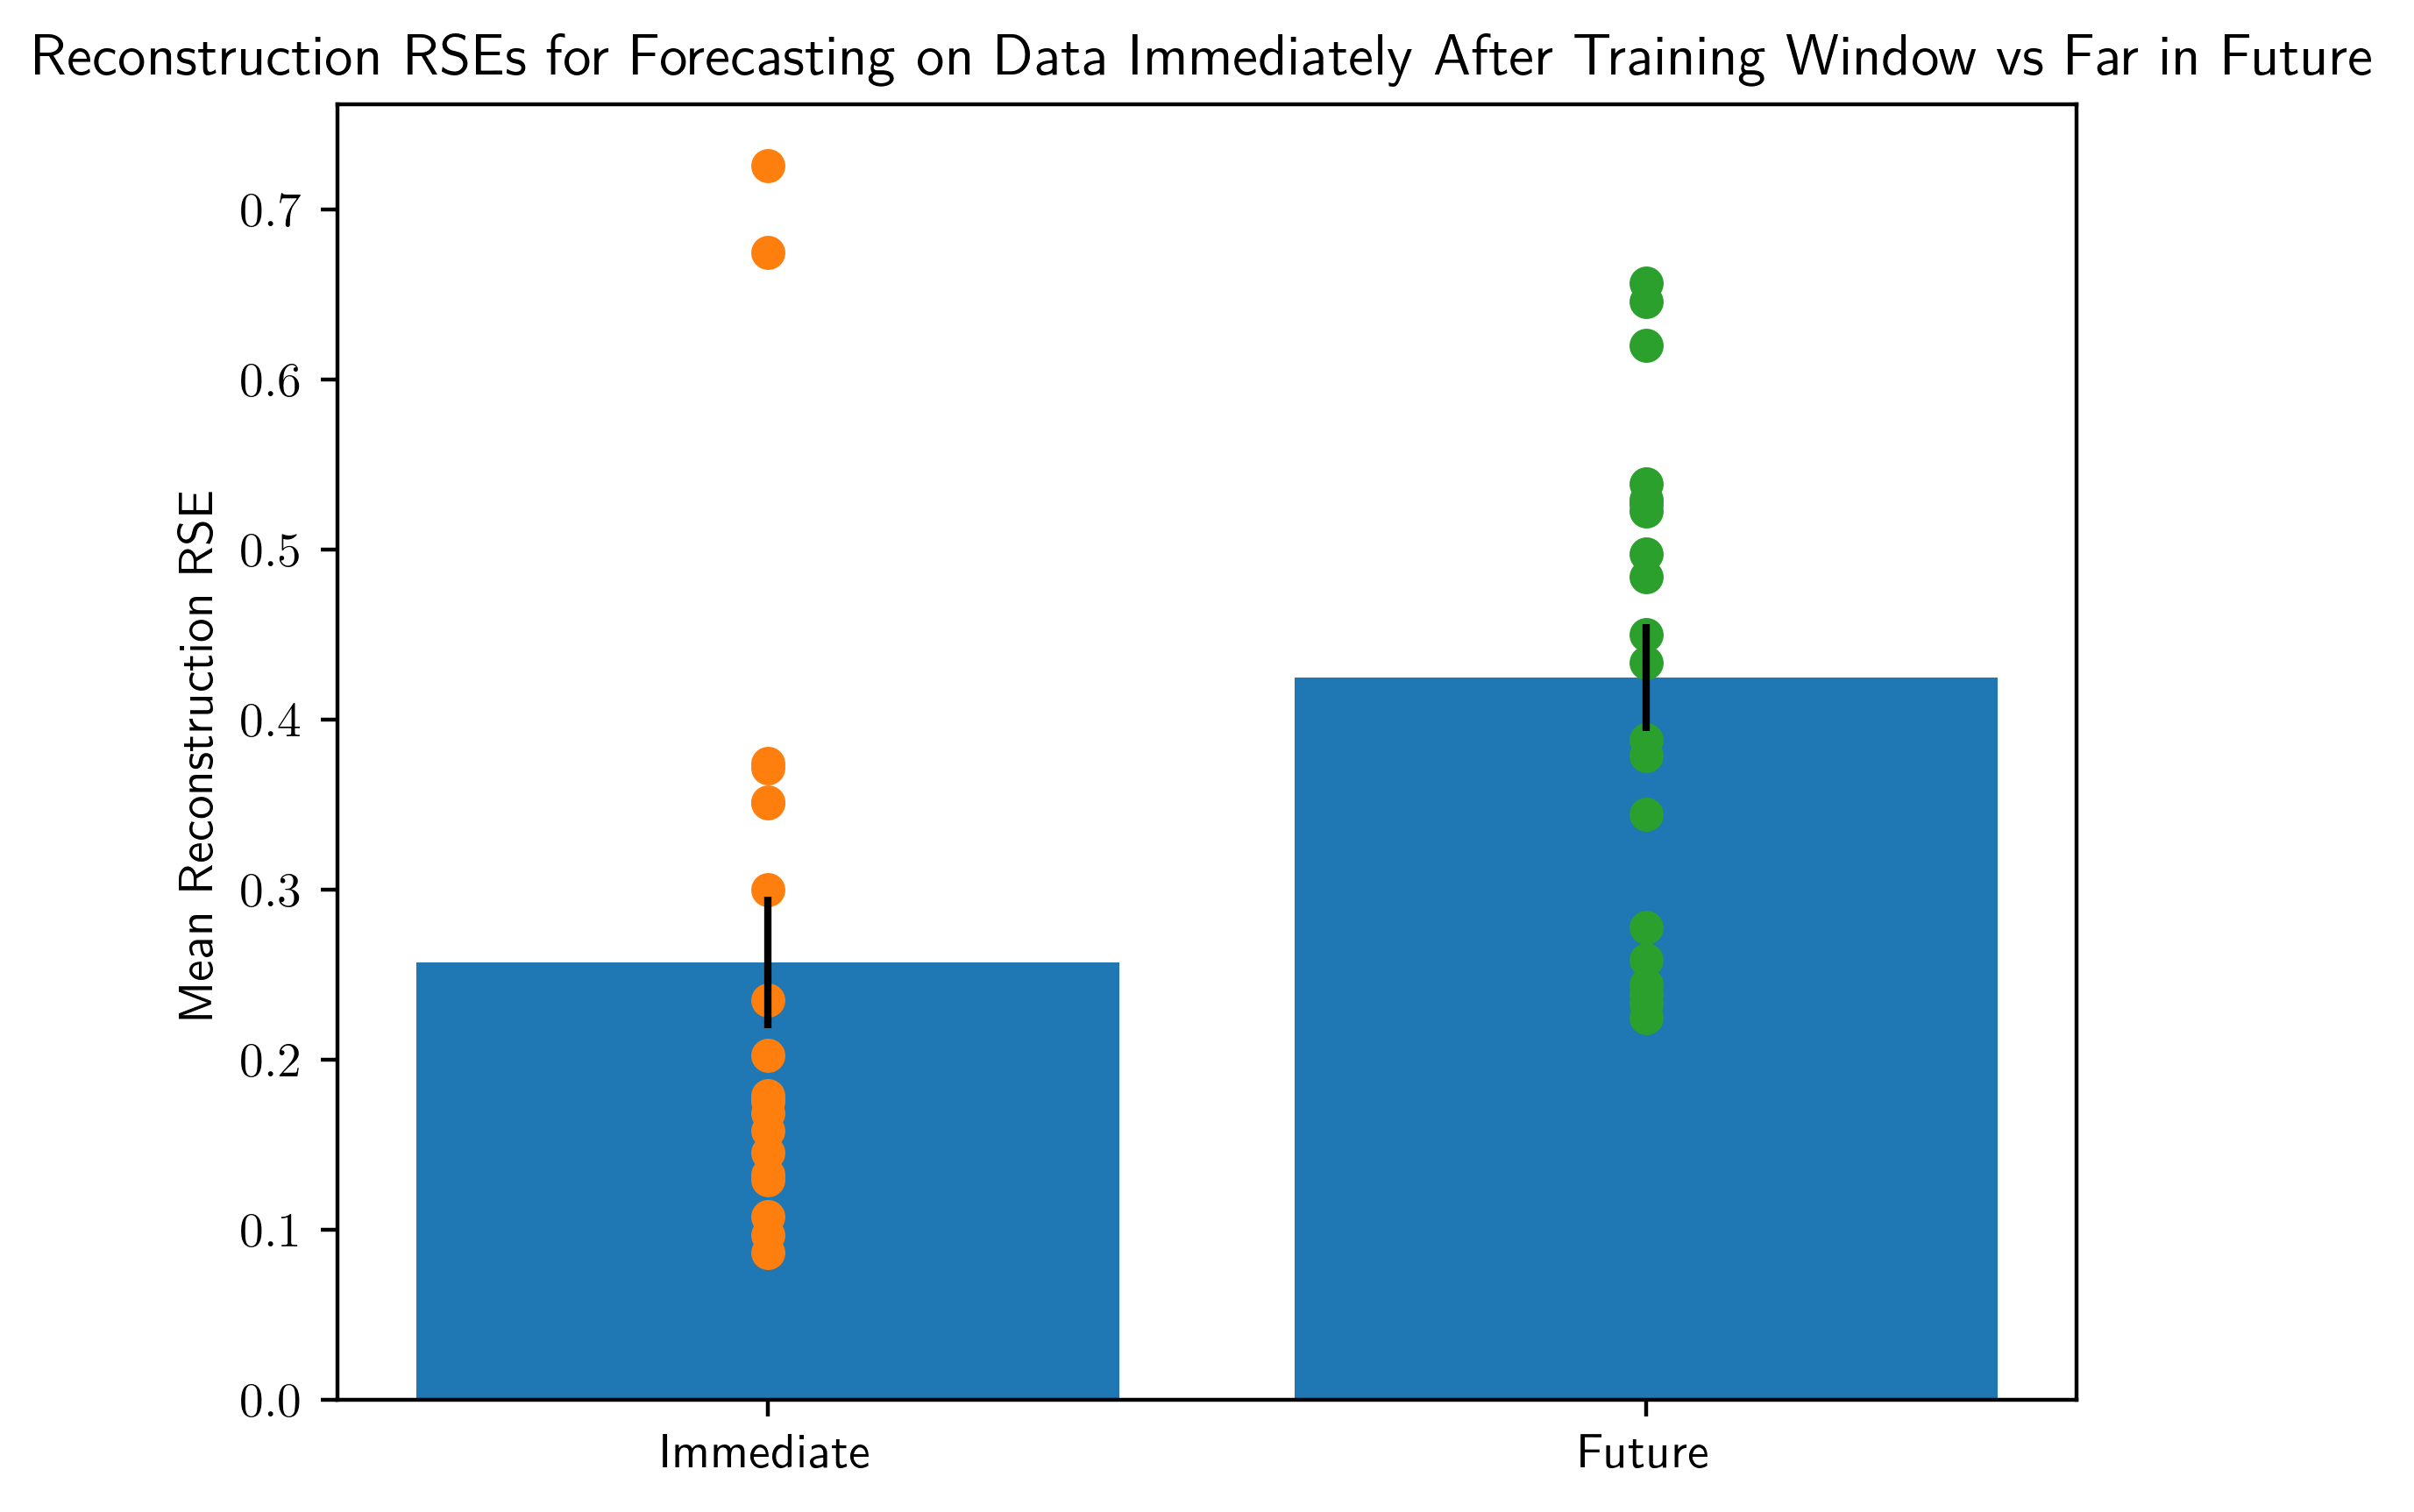

In [291]:
plt.bar(["Immediate","Future"],[np.mean(immediate_RSEs),np.mean(future_RSEs)],yerr=[np.std(immediate_RSEs)/np.sqrt(20),np.std(future_RSEs)/np.sqrt(20)])
plt.ylabel("Mean Reconstruction RSE")
plt.title("Reconstruction RSEs for Forecasting on Data Immediately After Training Window vs Far in Future")
plt.scatter(np.zeros_like(immediate_RSEs),immediate_RSEs)
plt.scatter(np.ones_like(future_RSEs),future_RSEs)

The difference in performance appears significant but less impressive than we would hope. However, as the datapoints show this is largely due to two outliers in the immediate forecast where the performance was very poor. Removing these outliers makes the performance difference more noticeable.

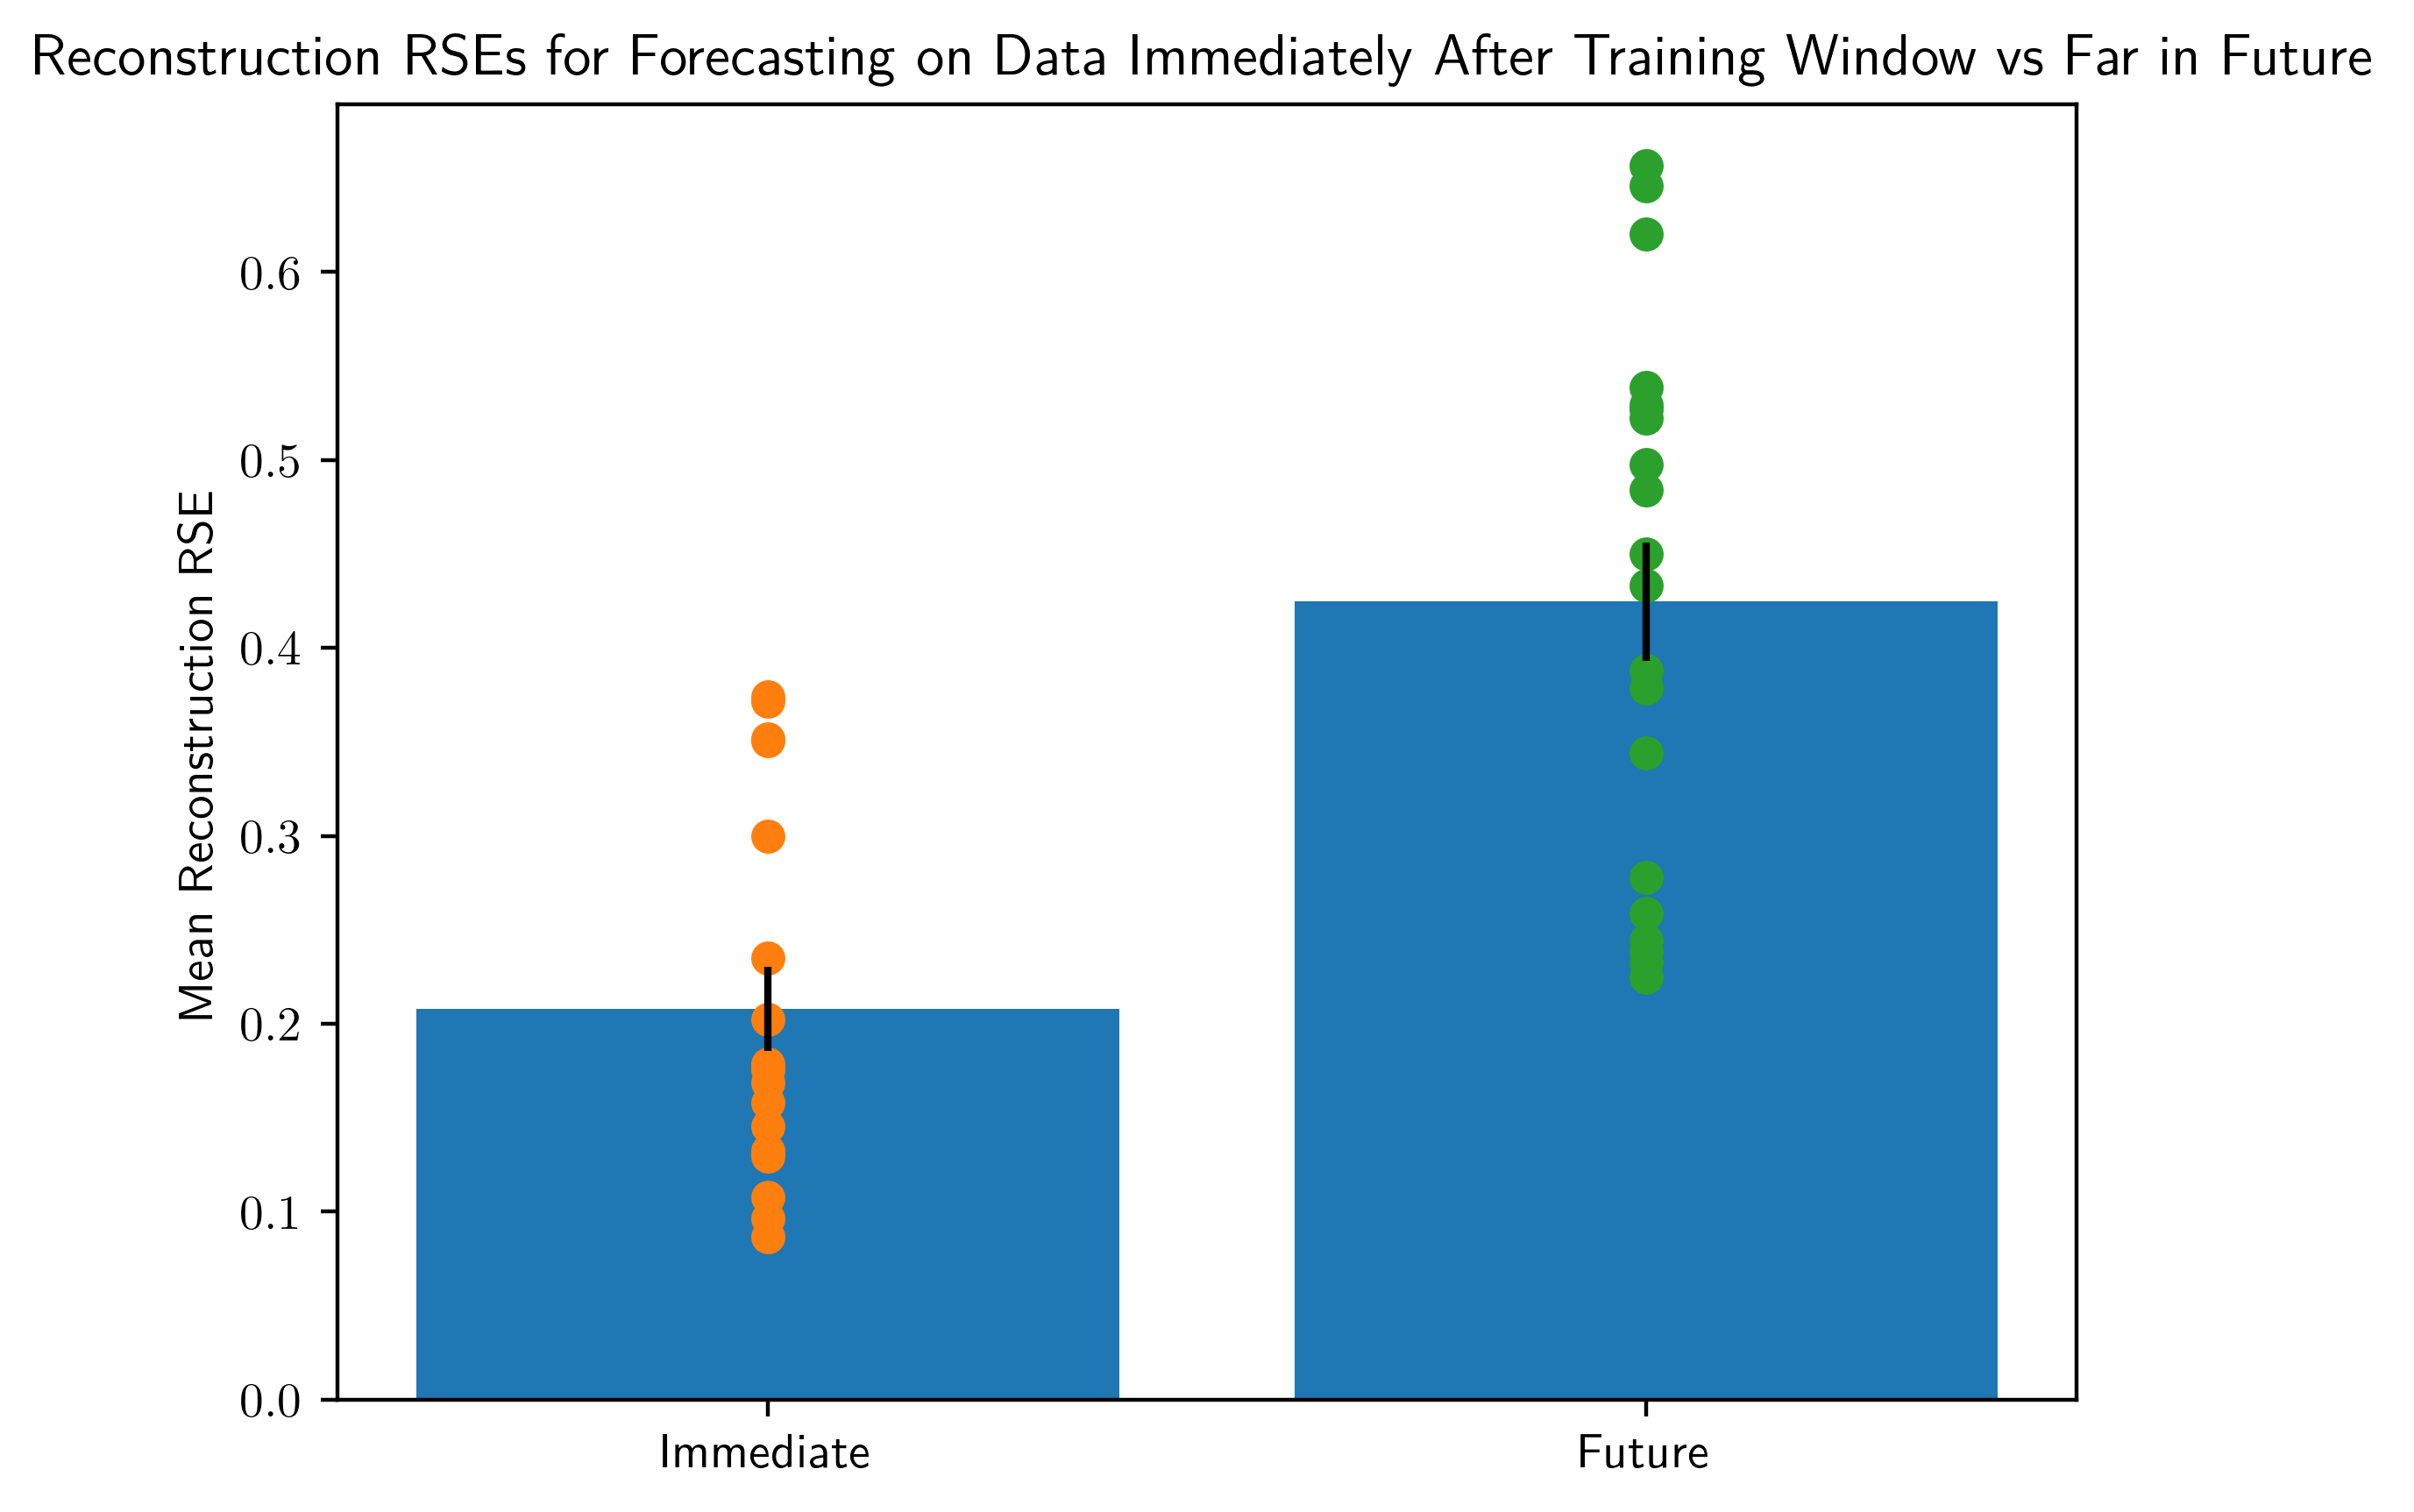

In [290]:
immediate_RSEs_filt = immediate_RSEs[immediate_RSEs < np.quantile(immediate_RSEs,0.94)]
plt.bar(["Immediate","Future"],[np.mean(immediate_RSEs_filt),np.mean(future_RSEs)],yerr=[np.std(immediate_RSEs_filt)/np.sqrt(18),np.std(future_RSEs)/np.sqrt(20)])
plt.ylabel("Mean Reconstruction RSE")
plt.title("Reconstruction RSEs for Forecasting on Data Immediately After Training Window vs Far in Future")
plt.scatter(np.zeros_like(immediate_RSEs_filt),immediate_RSEs_filt)
plt.scatter(np.ones_like(future_RSEs),future_RSEs)

We will now make a video showing the OptDMD "forecast" from a fit of the modes to timepoints 0-500 and the amplitudes to timepoints 500-600.

In [ ]:
# Load widefield spatial data
# This data is 560x560x2000, where the first two dimensions are pixels
# and the last dimension is SVD mode. We will keep only the top 50 modes
wf_spat = np.load('../Mouse Data/svdSpatialComponents.npy')
top50 = wf_spat[:,:,:50].copy()

# Set aside memory for all matrix multiplications we will do
matmul_out = np.empty((560,560))

# Compute first frame
USV = np.matmul(top50,SV_norm*SVn[:50,500],out=matmul_out)
# Delete wf_spat from memory
del wf_spat

In [ ]:
# Import packages for animations
import sys
import warnings
warnings.filterwarnings('ignore')
from matplotlib import animation, rc
rc('animation',html='html5')

# Regenerate best reconstruction
optdmd = BOPDMD(24)
optdmd.fit(SVn[:50,:500],np.arange(500))
t = np.arange(0,100)
exp_mat = np.exp(np.outer(optdmd.eigs[np.newaxis],t))
reconstruct, b = regress_optdmd(SVn[:50,500:600],optdmd.modes,exp_mat,24)

# We will create a 3x5 array of plots.
# The top row will be blank except for entry 
fig,ax = plt.subplots(1,2,sharex=True,sharey=True,constrained_layout=True)
true_ax = ax[0].imshow(USV)
ax[0].set_title('True Data')
reproduce_ax = ax[1].imshow(np.matmul(top50,SV_norm*np.real(reconstruct[:,0]),out=matmul_out))
ax[1].set_title("OptDMD Forecast")
im = []
dt = 0.0285
fig.suptitle("Reproducing Future Data with OptDMD (t= " + str(500*dt)+"s)",y=1.05)
#fig.colorbar(true_ax,ax=ax,ticks=np.arange(-2000,2000,400),format="%d")
plt.subplots_adjust(bottom=0.001, top=0.9, hspace=0)
def animate(t):
    print("At iteration " + str(t))
    # True data
    USV = np.matmul(top50,SV_norm*SVn[:50,500+t],out=matmul_out)
    true_ax.set_data(USV)
    true_ax.set_clim(-2000,2000)
    fig.suptitle("Reproducing Future Data with OptDMD (t= " + str((500+t)*dt)+"s)",y=1.05)
    # Reproduction
    USV = np.matmul(top50,SV_norm*np.real(reconstruct[:,t]),out=matmul_out)
    reproduce_ax.set_data(USV)
    reproduce_ax.set_clim(-2000,2000)
anim = animation.FuncAnimation(fig,animate,frames=99,save_count=None,repeat=False)
writermp4=animation.FFMpegWriter(fps=6)
anim.save('OptDMD Forecast.mp4',writer = writermp4)

# Fitting B as a Function of Time

In the above code, we fit a single vector of coefficients $b$ to the future data. An alternative would be to relearn $b$ after every $k$ time points, so that $b$ becomes a function of time. If $k=1$, then $b$ will become essentially a smooth function. If $k>1$, it will be a piecewise constant function.

First let's see what happens when $k=1$.

  0%|          | 0/100 [00:00<?, ?it/s]

Forecast Reconstruction RSE: 0.02310112827907104


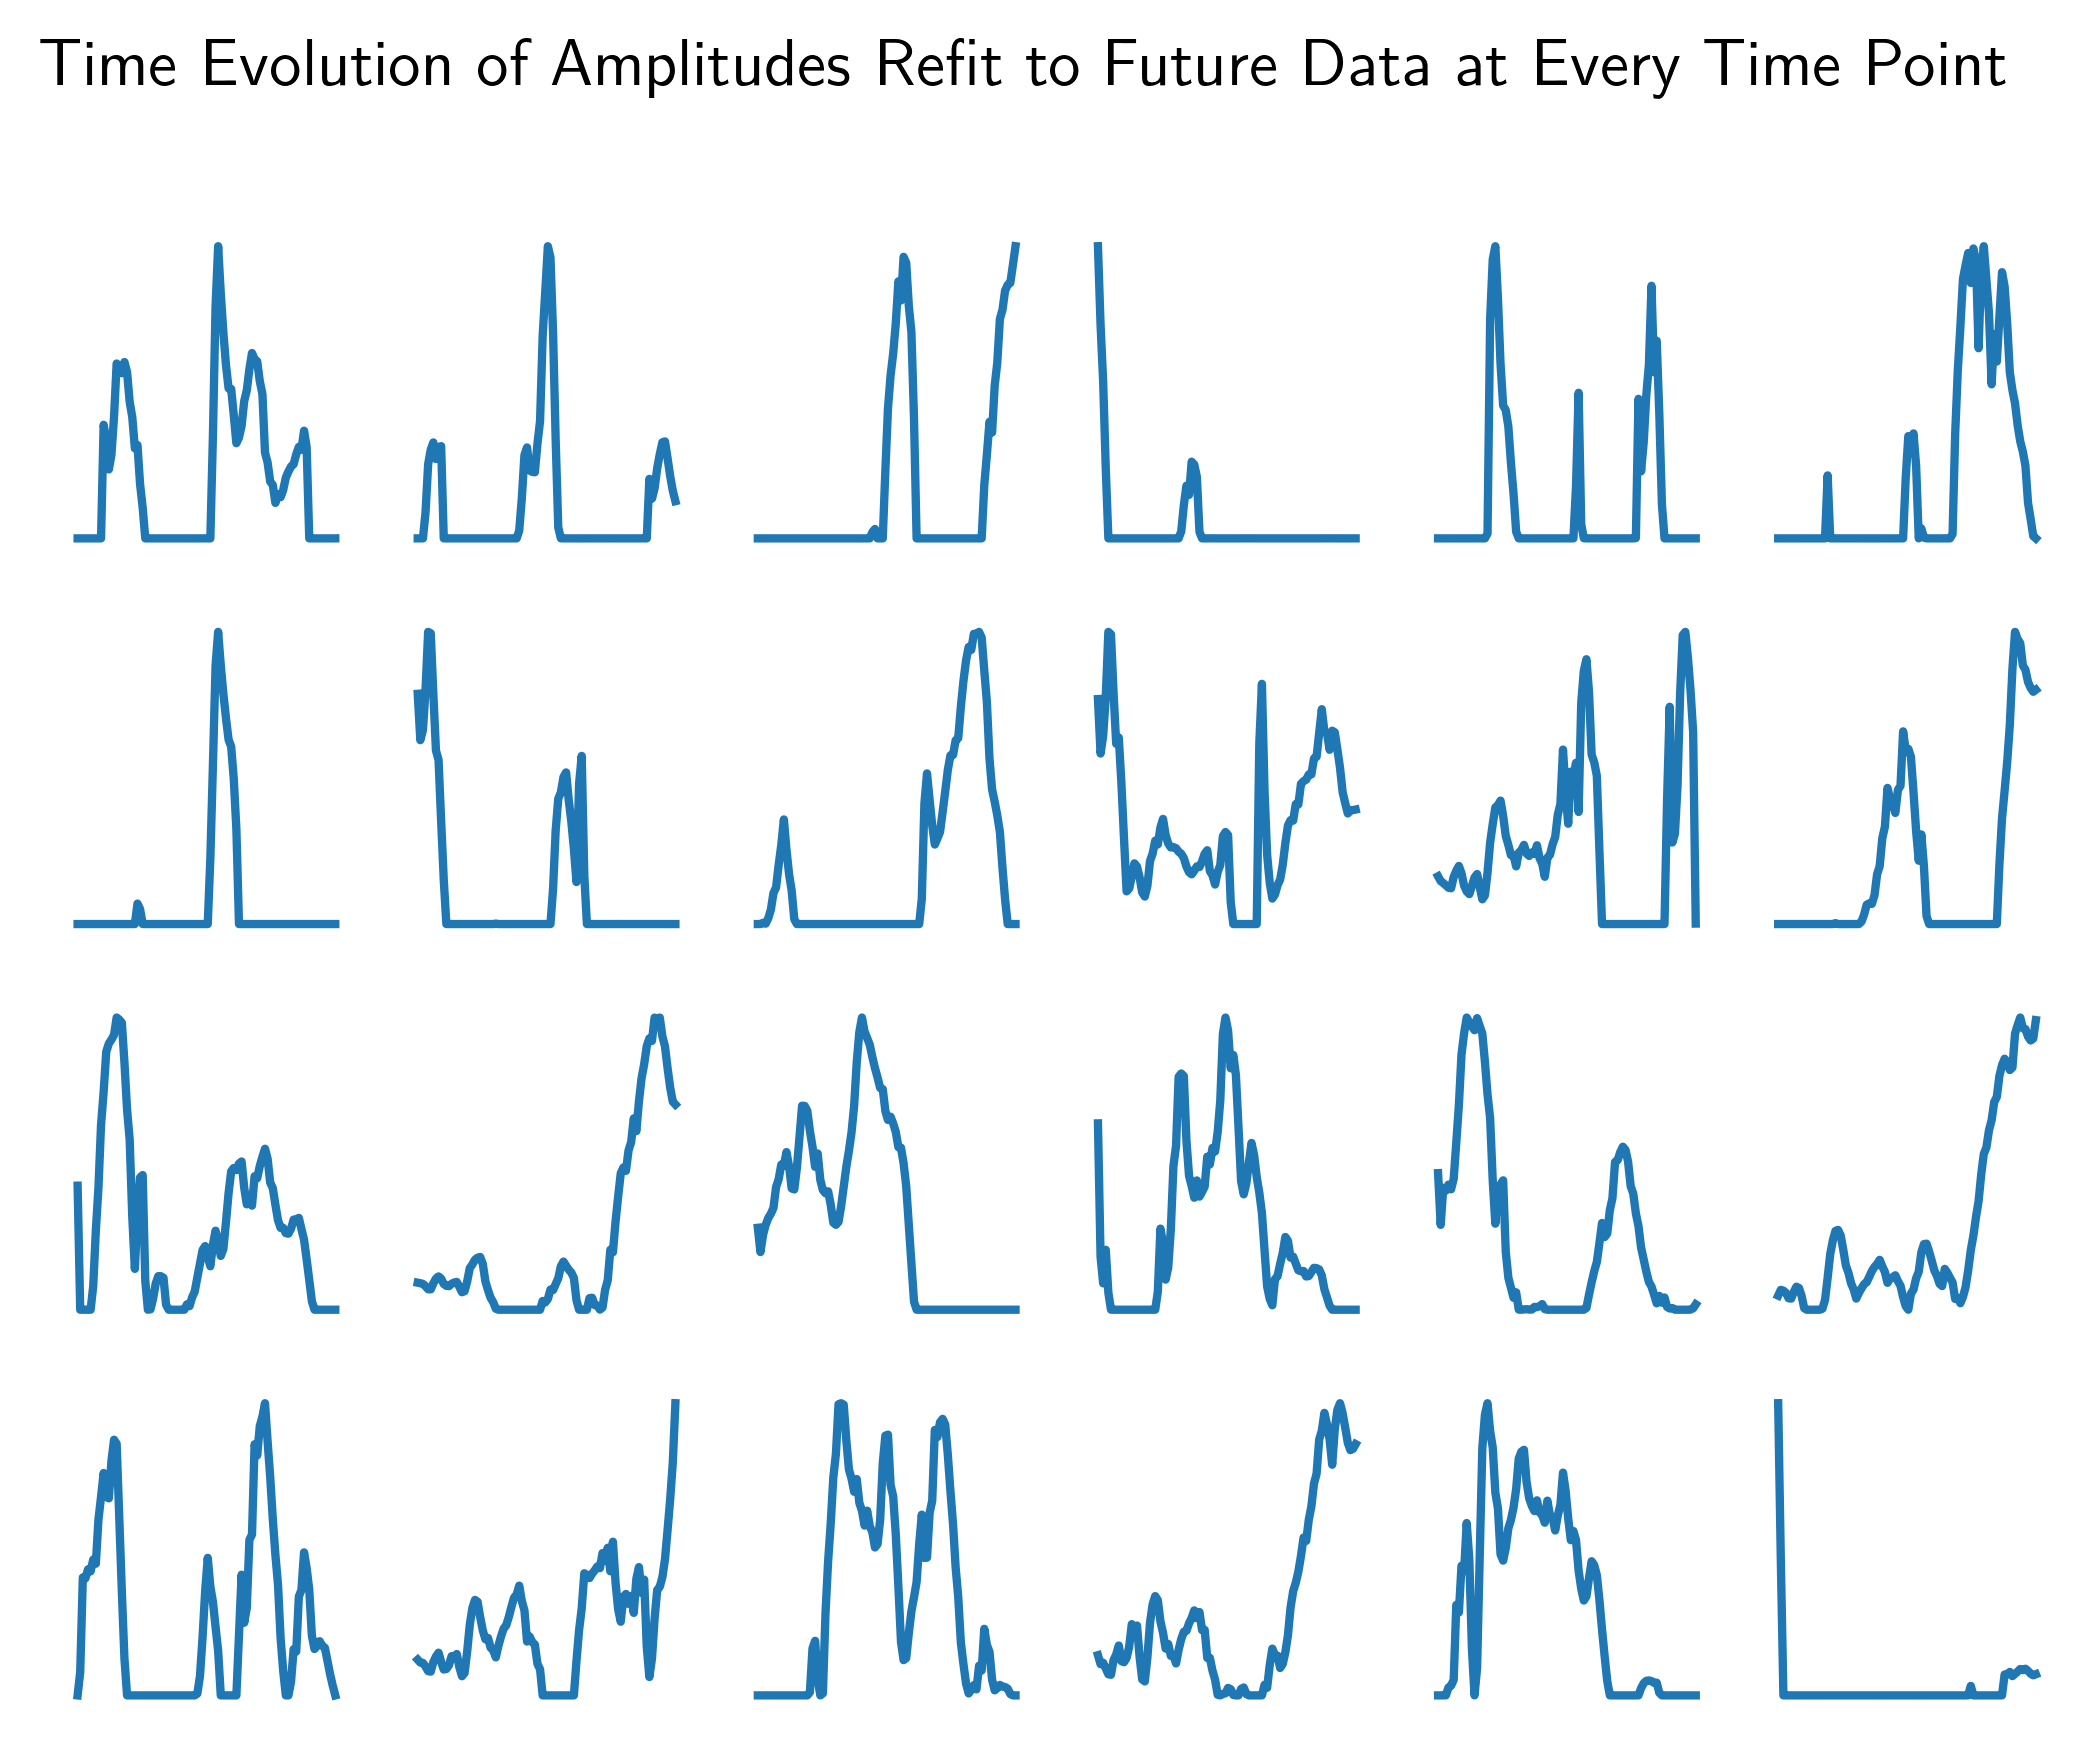

In [335]:
def fit_b(start: int, stop: int, forecast_length: int, r: int, k: int):
    """
    start: Beginning of training window
    stop: End of training window
    forecast_length: Number of timepoints beyond training window to forecast
    r: Rank of OptDMD Fit
    k: How many timesteps to take before refitting b. Should divide forecast_length
    """
    reconstruction = np.zeros((50,forecast_length))
    bt = np.zeros((r,forecast_length//k))
    optdmd = BOPDMD(r)
    optdmd.fit(SVn[:50,start:stop],np.arange(stop-start))
    t = np.arange(0,forecast_length)
    exp_mat = np.exp(np.outer(optdmd.eigs[np.newaxis],t))
    for i in tqdm(range(0,forecast_length,k)):
        reconstruction[:,i:i+k], bt[:,i//k] = regress_optdmd(SVn[:50,stop+i:stop+i+1],modes_mat,exp_mat[:,i][:,None],24,0)
    return reconstruction, bt

reconstruction, bt = fit_b(0,500,100,24,1)
print("Forecast Reconstruction RSE: " + str(RSE(reconstruction,SVn[:50,500:600])))
fig, ax = plt.subplots(4,6)
row = -1
for i in range(24):
    if i % 6 == 0:
        row += 1
    ax[row,i%6].plot(bt[i,:])
    ax[row,i%6].axis('off')
fig.suptitle("Time Evolution of Amplitudes Refit to Future Data at Every Time Point");

Unsurprisingly the RSE is very low, since we have added a lot of complexity to the model. Let's visualize the amplitudes as they change over time.

The common pattern here seems to be that many of the amplitudes are zero or small for a while, suddenly "turn on", and then turn back off. Maybe this is detecting transients, or maybe this is just fitting noise. I am not sure at this point.

Next let's try $k=10$.

  0%|          | 0/10 [00:00<?, ?it/s]

Forecast Reconstruction RSE: 0.08958043760068593


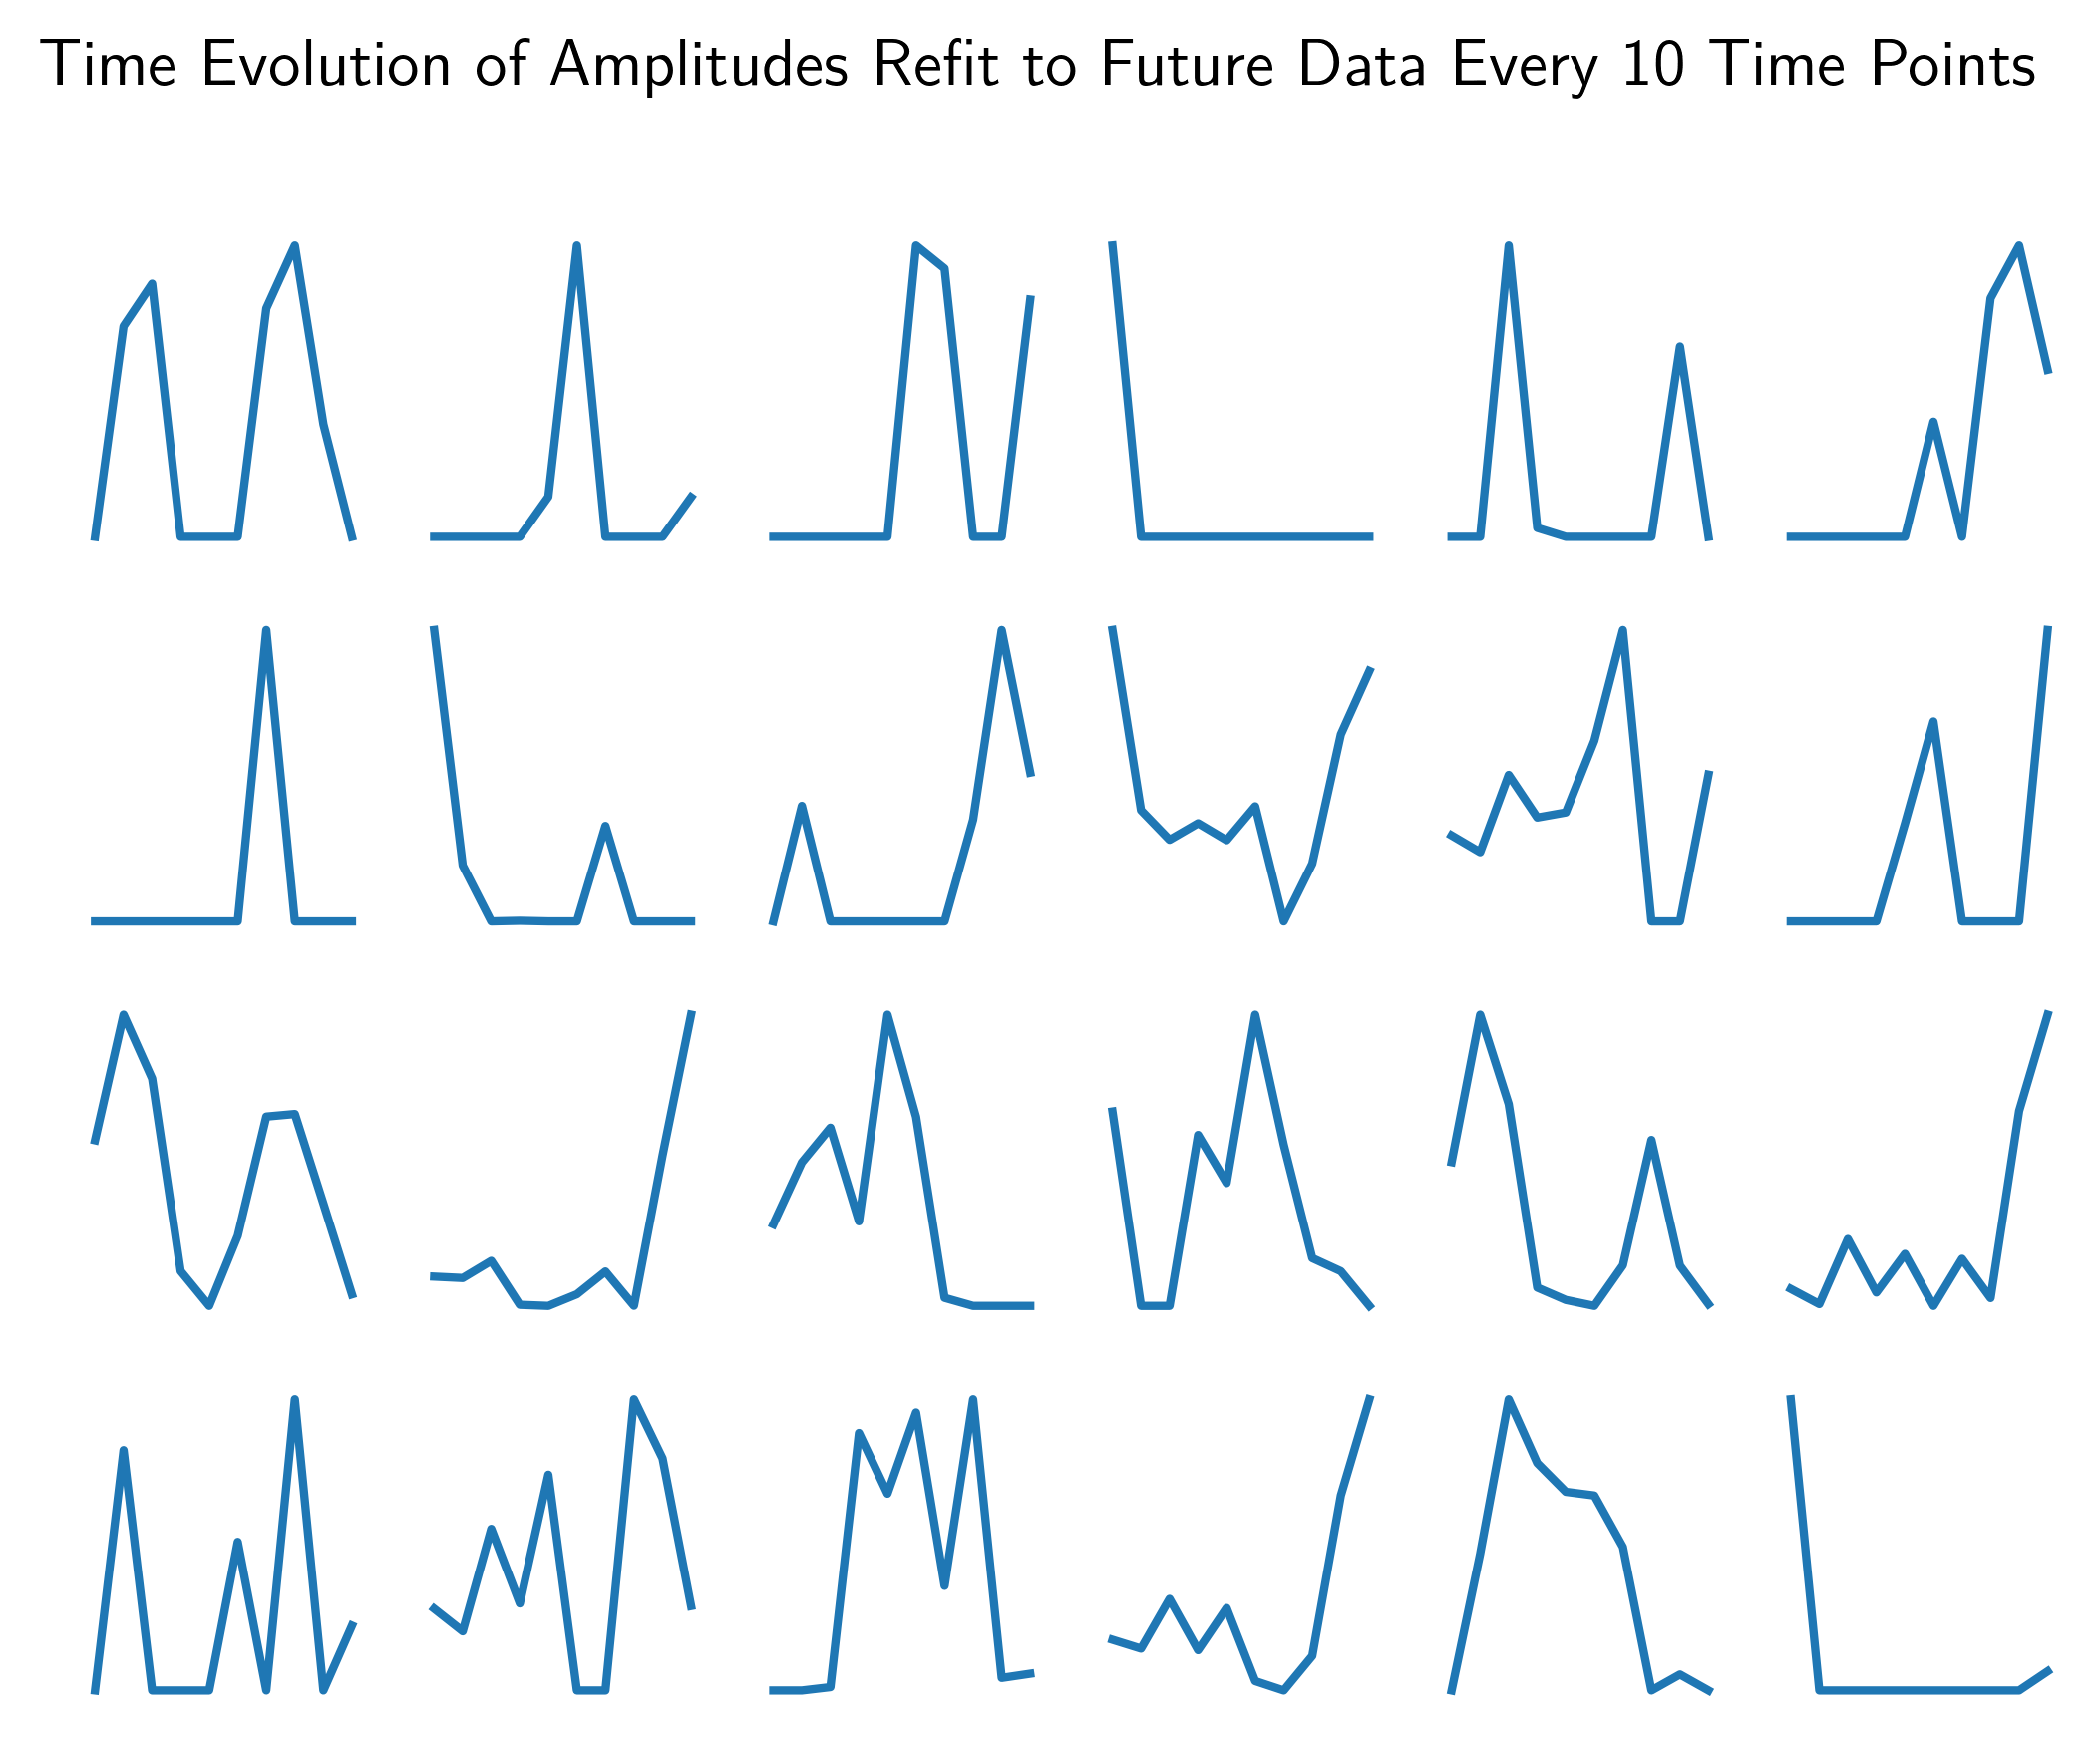

In [330]:
reconstruction, bt = fit_b(0,500,100,24,10)
print("Forecast Reconstruction RSE: " + str(RSE(reconstruction,SVn[:50,500:600])))
fig, ax = plt.subplots(4,6)
row = -1
for i in range(24):
    if i % 6 == 0:
        row += 1
    ax[row,i%6].plot(bt[i,:])
    ax[row,i%6].axis('off')
fig.suptitle("Time Evolution of Amplitudes Refit to Future Data Every 10 Time Points");

Of course, with this we get the same dynamics as with $k=1$, but with less jitter.

# Forecasting for True Rank Detection

Another interesting application of this method is enforce that each amplitude $b_j$ is greater than or equal to some minimum number and compute the forecast RSE. Because of the constraint on the amplitudes, if the rank of the underlying dynamics is $r$ and we fit $r+k$ modes, then $k$ of the modes will be fit to noise and will reduce the RSE on future data. In this way we can get another estimate of the true rank $r$ of our data by looking at when adding more modes hurts the forecast RSE.

I will impose the constraint that $b_j>10^{-5}$ for each $j$. We will fit 20 non-overlapping consecutive 500 timepoint trials. For each trial, we will then the modes with new amplitudes to the 100 timepoints after the trial, and compute this forecast RSE.

In [67]:
# Modes to try = range(start,stop+1)
stop = 40
start = 10
# Number of 500 timepoint trials = k
k = 20
errors = np.zeros((stop-start+1,k))

for r in tqdm(range(start,stop+1),leave=False,desc='Mode Loop'):
    for i in tqdm(range(k),leave=False,desc='Trial Loop'):
        # Create test and train sets
        train_V = SVn[:50,i*500:(i+1)*500]
        forecast_V = SVn[:50,(i+1)*500:(i+1)*500+100]
        # Fit optDMD
        optdmd = BOPDMD(svd_rank=r)
        optdmd.fit(train_V,np.arange(500))
        # Create mode and exponential matrices for each fit
        t = np.arange(0,100)
        exp_mat = np.exp(np.outer(optdmd.eigs[np.newaxis],t)) # Matrix of exponentials
        # Regress on next 100 timepoints
        reconstruct,  _ = regress_optdmd(forecast_V,optdmd.modes,exp_mat,r,1e-5)
        # Compute RSEs
        errors[r-start,i] = RSE(reconstruct,forecast_V)
        
sems = np.std(errors,axis=1)/np.sqrt(20)
mean_errors = np.mean(errors,axis=1)
x = np.arange(10,41)
plt.plot(x,deg2fit[0]*x**2+deg2fit[1]*x+deg2fit[2],label="Quadratic Fit")
plt.plot(x,mean_errors,label="Mean Forecast Reconstruction RSE")
plt.fill_between(x,mean_errors-sems,mean_errors+sems,alpha=0.5)
plt.xlabel("Number of Modes Used")
plt.ylabel("Reconstruction RSE")
plt.title("Reconstruction RSEs from Fitting Modes to Future Data")
plt.legend();

Mode Loop:   0%|          | 0/31 [00:00<?, ?it/s]

Trial Loop:   0%|          | 0/20 [00:00<?, ?it/s]

Trial Loop:   0%|          | 0/20 [00:00<?, ?it/s]

Trial Loop:   0%|          | 0/20 [00:00<?, ?it/s]

Trial Loop:   0%|          | 0/20 [00:00<?, ?it/s]

...

Trial Loop:   0%|          | 0/20 [00:00<?, ?it/s]

Trial Loop:   0%|          | 0/20 [00:00<?, ?it/s]

Trial Loop:   0%|          | 0/20 [00:00<?, ?it/s]

Trial Loop:   0%|          | 0/20 [00:00<?, ?it/s]

Trial Loop:   0%|          | 0/20 [00:00<?, ?it/s]

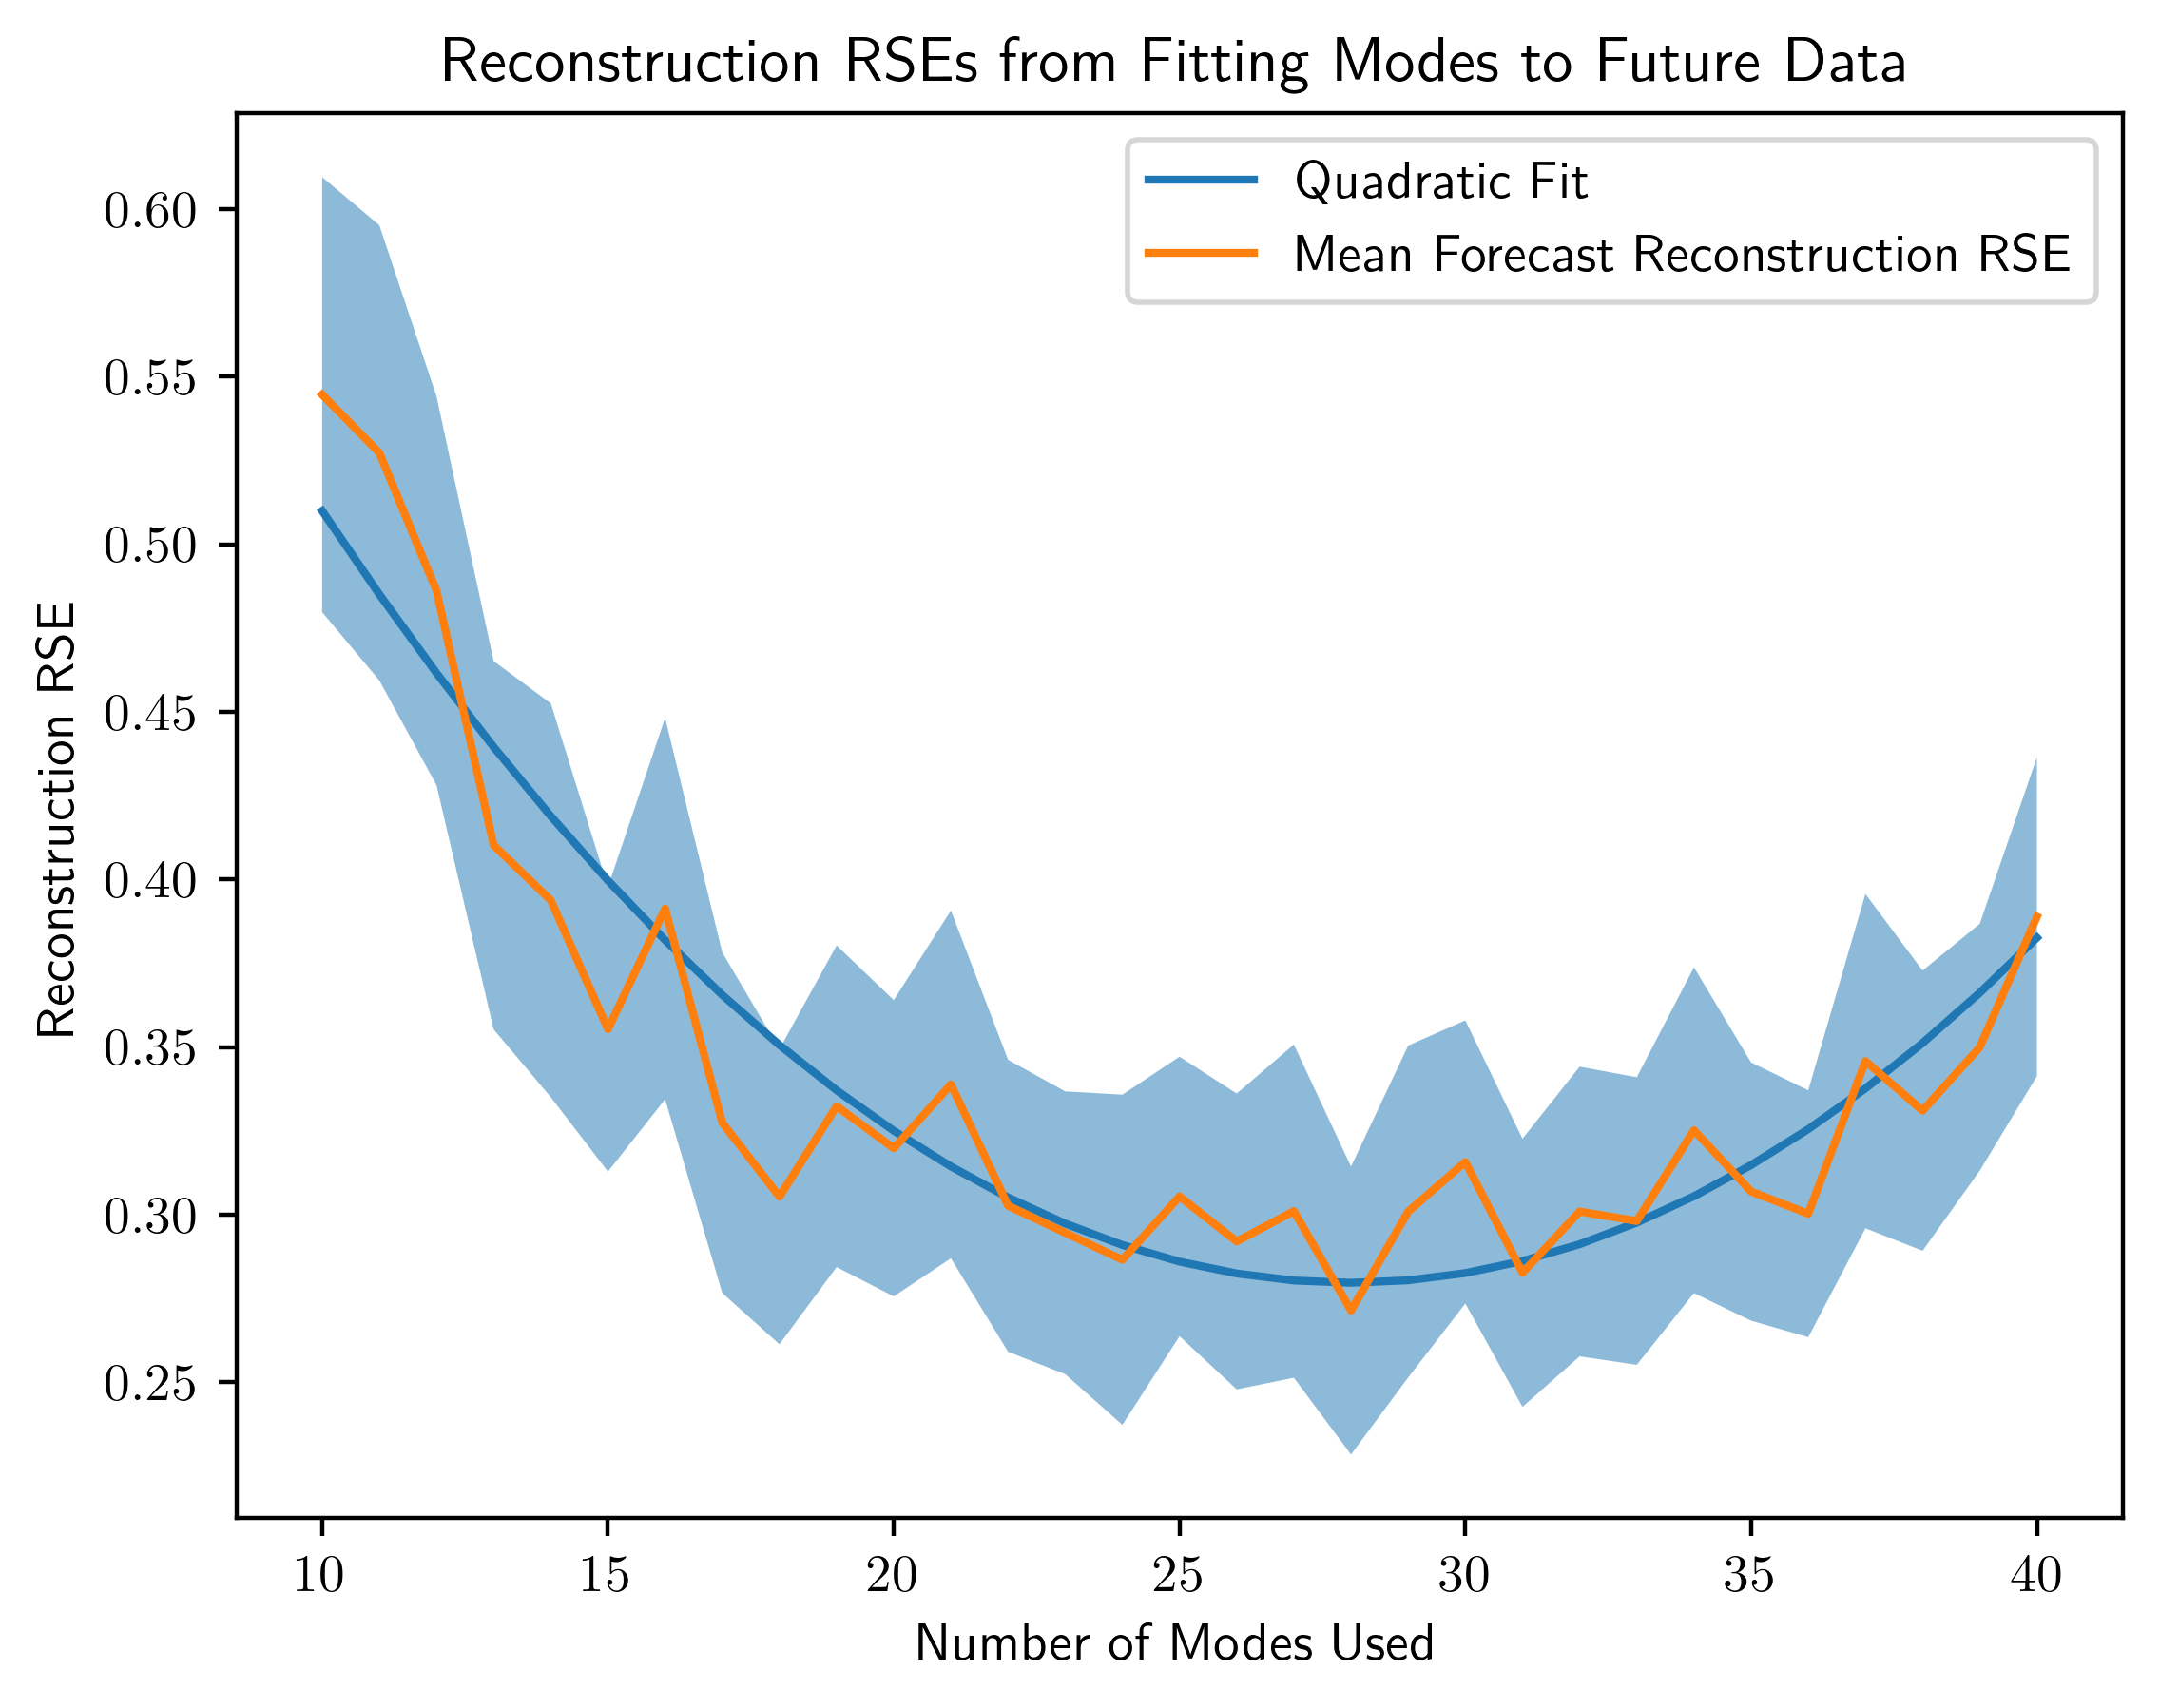

The quadratic fit indicates that the right number of modes is around 26-28, although as the SEM window shows, the performance there is almost certainly not significantly different from the performance with 22-26 modes. In any case, the true rank of the dynamics is probably not far from the rank predicted by the optimal SVD hard threshold rule (24).

Note that the reconstruction RSE is high in all cases here because the threshold on the amplitudes is rather constraining. With 24 modes and the only constraint being that all amplitudes are positive, we expect forecast reconstruction RSEs more like 10-20%.

# Comparison to PCA/POD

Next let's compare the stability of OptDMD modes with PCA/POD modes. In the PCA reconstruction, we replace $\Phi$ with $U$ and $\Omega$ with $V$.

  0%|          | 0/10 [00:00<?, ?it/s]

Text(0.5, 1.0, 'Average Forecast Reconstruction RSEs ')

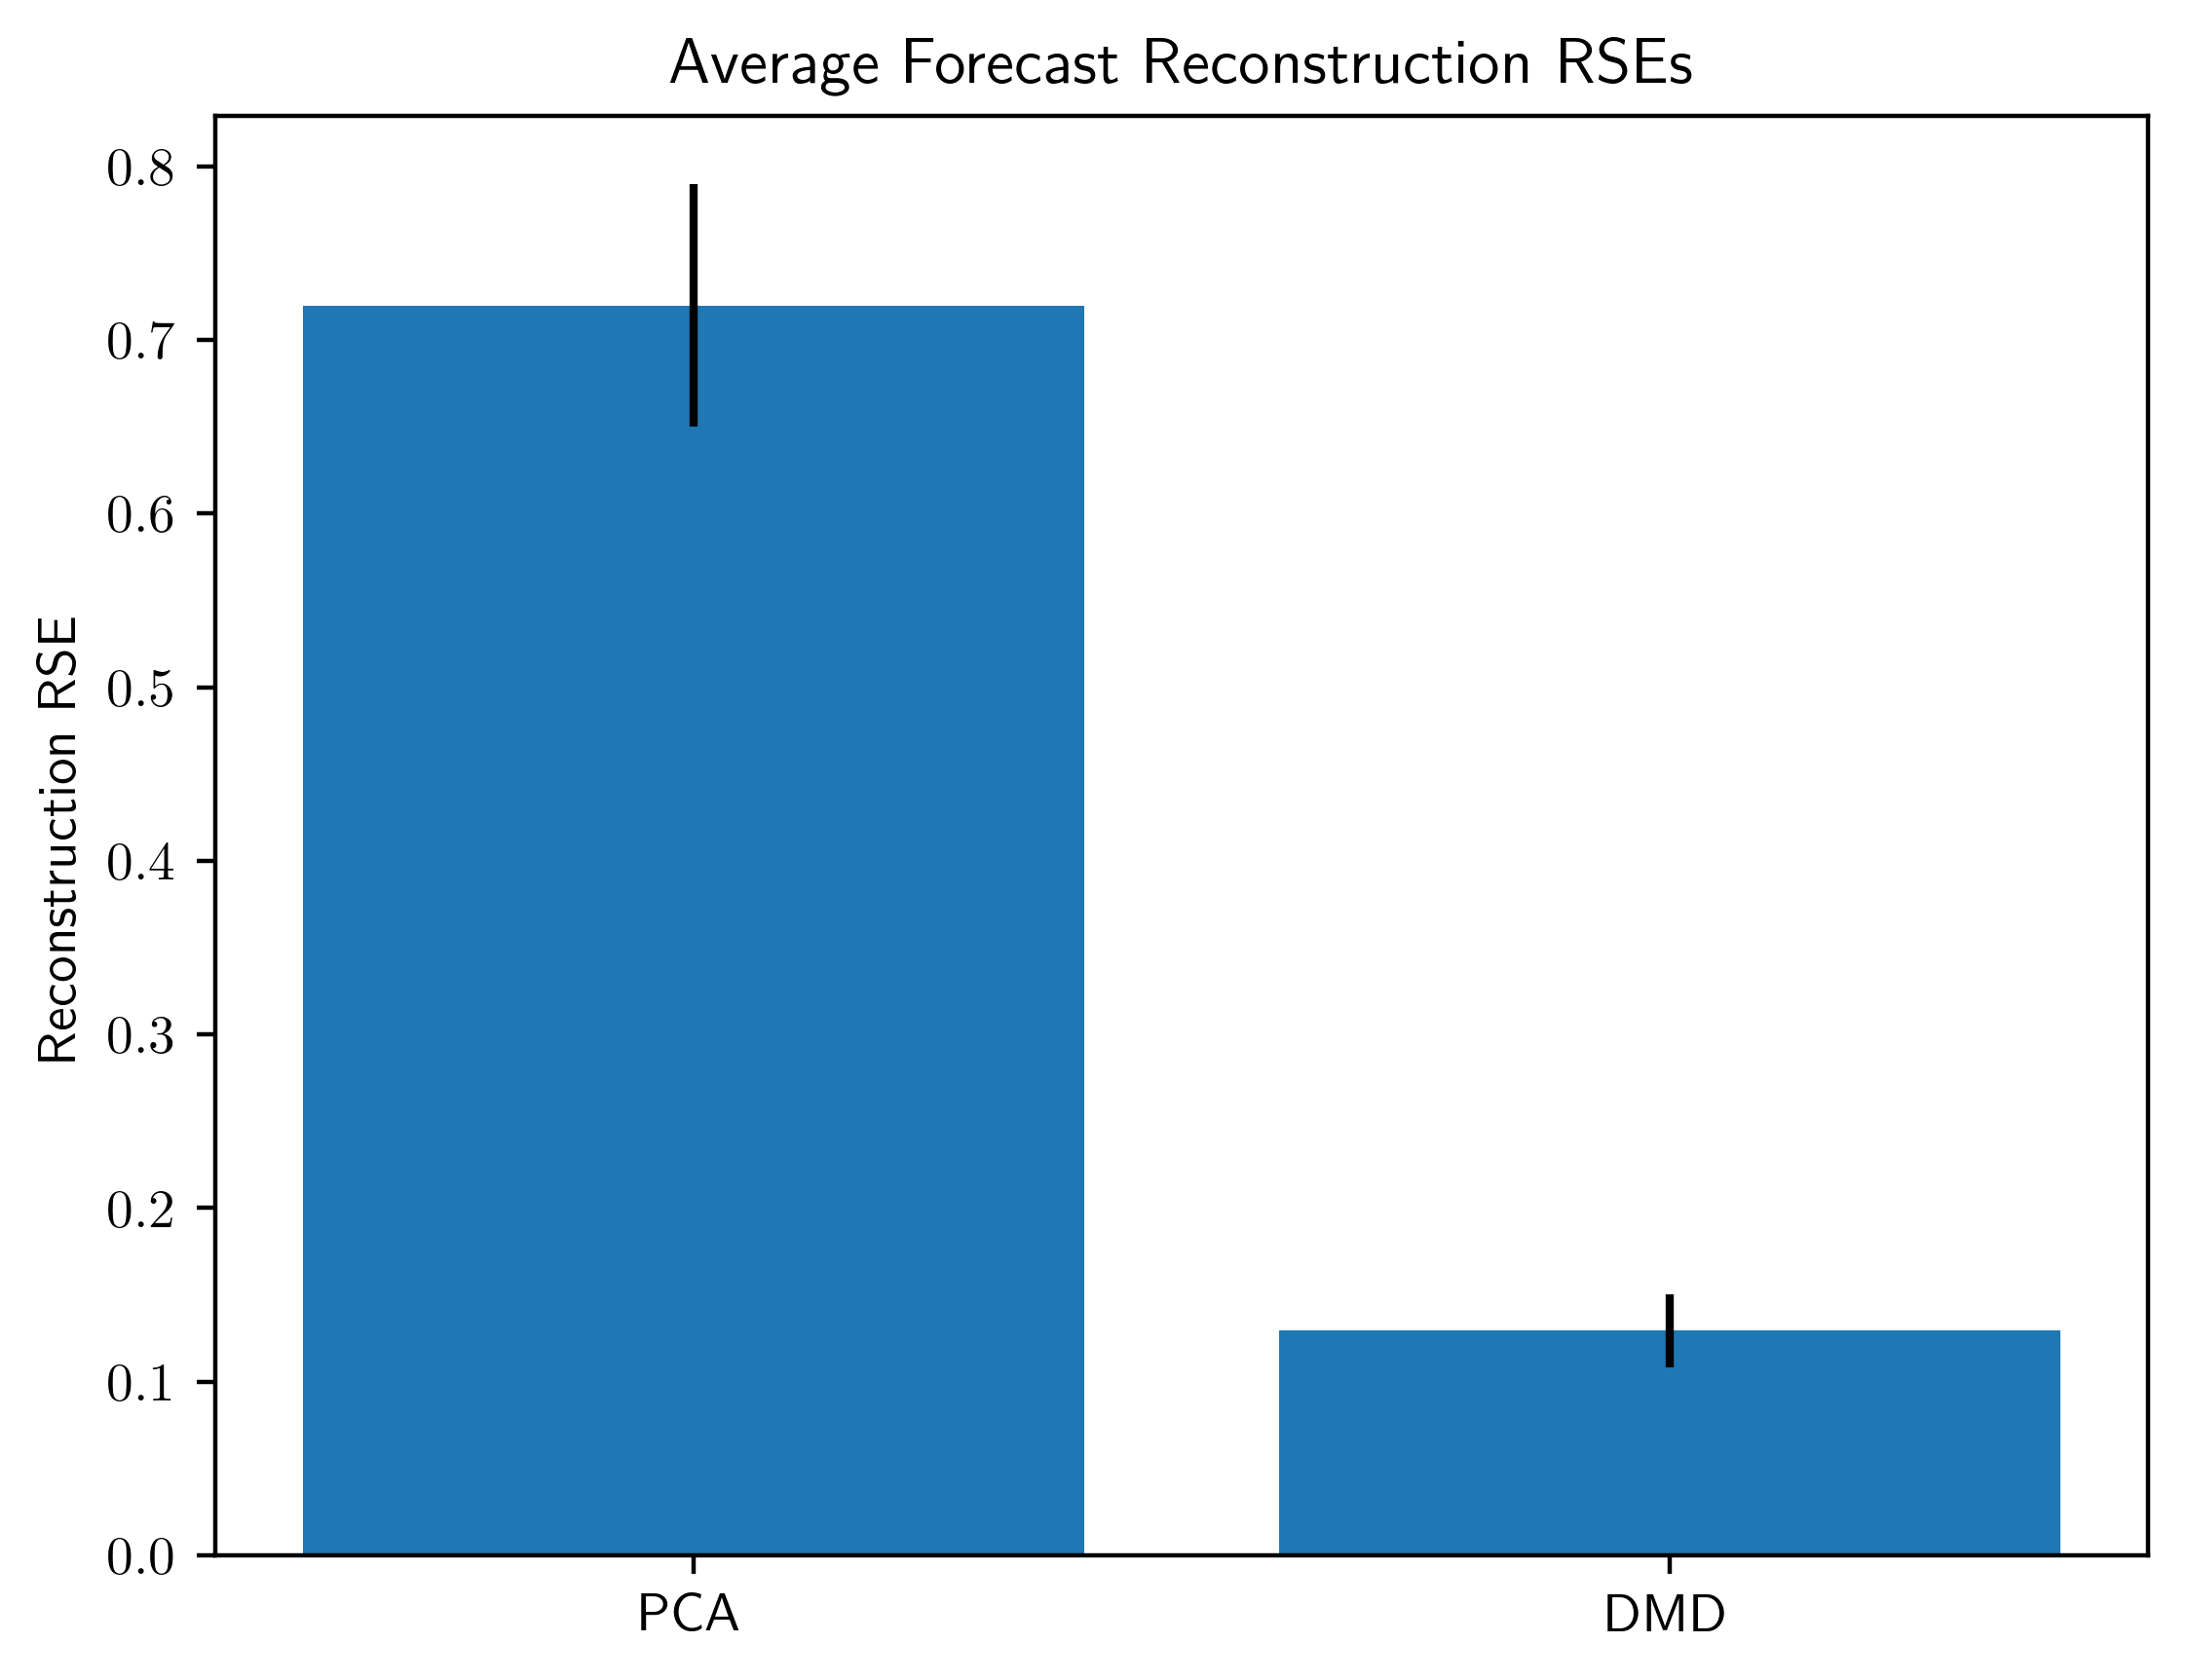

In [3]:
DMD_errors_regress = []
PCA_errors_regress = []
for i in tqdm(range(10)):
    # Fit OptDMD
    optdmd = BOPDMD(svd_rank=24)
    optdmd.fit(SVn[:50,(i*500):(i+1)*500],np.arange(500))
    
    # Get matrix of exponentials
    t = np.arange(1,101)
    exp_mat = np.exp(np.outer(optdmd.eigs[np.newaxis],t)) 
    
    # Fit SVD
    U,S,V = np.linalg.svd(SVn[:50,i*500:(i+1)*500],full_matrices=False)
    U24 = U[:,:24]
    S24 = S[:24]
    V24 = V[:24,:]
    
    # Get reconstructions
    reconstruct_DMD,b_DMD = regress_optdmd(SVn[:50,(i+1)*500:(i+1)*500+100],modes_mat,exp_mat,24)
    reconstruct_pca,b_pca = regress_optdmd(SVn[:50,(i+1)*500:(i+1)*500+100],U24.astype('complex128'),V24[:,:100],24)
    
    DMD_errors_regress.append(RSE(reconstruct_DMD,SVn[:50,(i+1)*500:(i+1)*500+100]))
    PCA_errors_regress.append(RSE(reconstruct_pca,SVn[:50,(i+1)*500:(i+1)*500+100]))
    
plt.bar(['PCA','DMD'],[np.mean(PCA_errors_regress),np.mean(DMD_errors_regress)],yerr=[np.std(PCA_errors_regress)/np.sqrt(10),np.std(DMD_errors_regress)/np.sqrt(10)])
plt.ylabel("Reconstruction RSE")
plt.title("Average Forecast Reconstruction RSEs ")

One could fairly argue that this is not a perfect comparison for several reasons, such as POD modes being orthonormal while the OptDMD modes are not. But the performance gap is very large, so hopefully this gives us some indication that the dynamically-informed OptDMD modes are more temporally stable than methods that are not dynamically informed such as PCA.

# Final Comments

Not shown here, but I have also tried to use the matrix of exponentials from the forecast set (say, time points 500 to 600), the modes from the train set (e.g. time points 0 to 500), and then learn the coefficients with regression. This does not work at all unfortunately; the RSEs are consistently about 1. It seems that the spatial and temporal aspects of the modes may need to go together.

I have also tried adding an $L_1$ penalty to the fit to induce sparsity, but selecting for modes with this method has led to very poor performance, so I have not included the result here. However, with a small $L_1$ penalty on a fit with 50 possible modes, the number of modes with nonzero amplitudes does drop to 24-26.

In the future, I would like to apply this method with HankelDMD modes. It's not obvious how to do this since the spatial/temporal modes learned by HankelDMD are used to reconstruct the Hankel matrix version of the original data rather than the original data itself.